# Modul 6 — Operasi Agregasi dan Transformasi Struktural

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-06/06_agregasi.ipynb`**; seluruh
keluaran modul ditulis ke folder `dw-module-06/` itu. Modul ini membaca keluaran acuan Modul 4
yang disediakan di **`data/acuan/`**: `transaksi_m04.parquet`, `produk_m04.parquet`, dan
`pelanggan_m04.parquet` (bukan keluaran Modul 4 Anda sendiri, sehingga kesalahan di Modul 4 tidak
terbawa ke sini). Unduh `data-acuan-modul-06.zip` di halaman modul dan ekstrak di folder `data-wrangling/`; isinya masuk ke `data/acuan/`. Dataset mentah disiapkan lewat panel *Dataset di laptop* halaman modul
(Local Runner menyala). Buku ajar: Bab 7 (7.1–7.5).

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 6.1–6.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama** pada butir lain (pelanggan, kohort, kanal), dan pertanyaan analisis menanyakan alasan di
balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` dan `data/acuan/` bersifat *read-only* — jangan menulis ke sana.
2. Setiap tabel ringkasan menyebut butirnya dan direkonsiliasi dengan tabel asal lewat `assert`.
3. Tidak ada baris yang hilang diam-diam: pesanan tanpa waktu, produk tanpa kategori, dan pembeli tamu tetap dihitung atau dikeluarkan dengan alasan tertulis.
4. Rasio dihitung dari jumlah pembilang dibagi jumlah penyebut, bukan dari rata-rata atas rata-rata.
5. Setiap keputusan dicatat pada `log-keputusan.csv` di akar workspace.
6. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Butir dan kunci: dari baris pesanan ke pesanan

### A.1 Menyiapkan notebook

In [42]:
import shutil
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "raw").is_dir()), None)
if ROOT is None:   # dataset mentah belum disiapkan di laptop ini
    raise FileNotFoundError(
        "Folder data/raw/ (dataset mentah) belum ada di folder data-wrangling/. Di aplikasi "
        "DSWorkbench, nyalakan Local Runner lalu tekan Siapkan berkas modul pada modul ini; "
        "dataset disiapkan ke data/raw/. Setelah itu jalankan ulang sel ini.")
M04 = ROOT / "data" / "acuan"   # keluaran acuan Modul 4 (disediakan)
MODUL = ROOT / "dw-module-06"      # folder tempat Workbench menyimpan notebook ini
LOG = ROOT / "log-keputusan.csv"
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 2026
pd.set_option("display.width", 150)

MASUKAN = ["transaksi_m04.parquet", "produk_m04.parquet", "pelanggan_m04.parquet"]
kurang = [f for f in MASUKAN if not (M04 / f).exists()]
if kurang:
    raise FileNotFoundError(f"Belum ada di {M04}: {', '.join(kurang)}. "
                            "Unduh data-acuan-modul-06.zip di halaman modul dan ekstrak di folder data-wrangling/.")
t4 = pd.read_parquet(M04 / "transaksi_m04.parquet")
produk = pd.read_parquet(M04 / "produk_m04.parquet")
pelanggan = pd.read_parquet(M04 / "pelanggan_m04.parquet")

KUNCI = ["id_pesanan", "baris_ke"]                   # kunci tabel transaksi (kontrak Modul 4)
assert not t4.duplicated(KUNCI).any(), "kunci (id_pesanan, baris_ke) tidak unik; periksa ulang Modul 4"
assert produk.kode_produk.is_unique and pelanggan.id_pelanggan.is_unique
print("Akar repositori :", ROOT.name)
print("transaksi_m04   :", t4.shape, "| produk_m04:", produk.shape, "| pelanggan_m04:", pelanggan.shape)

Akar repositori : data-wrangling
transaksi_m04   : (24000, 46) | produk_m04: (850, 15) | pelanggan_m04: (5760, 18)


In [43]:
def rp(x: float) -> str:
    """Rupiah berformat Indonesia untuk teks bukti: 1234567 -> 'Rp1.234.567'."""
    return f"Rp{x:,.0f}".replace(",", ".")


def angka(x: float, d: int = 1) -> str:
    """Angka berformat Indonesia untuk teks bukti: 90.66 -> '90,7'."""
    return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")


def juta(x: float, d: int = 1) -> str:
    """Rupiah dalam juta untuk teks bukti: 8023194575 -> '8.023,2 juta'."""
    return angka(x / 1e6, d) + " juta"


B = {}          # angka-angka temuan; dipakai lagi pada kolom bukti log keputusan

### A.2 Satu baris mewakili apa?

In [44]:
KOLOM_PERIKSA = ["kanal", "id_pelanggan", "id_entitas", "waktu_wib", "kota_tujuan", "provinsi_tujuan",
                 "kurir", "metode_bayar", "status", "kode_produk", "jumlah", "ongkir", "total_bayar",
                 "lama_kirim_hari", "rating_ulasan"]
per_pesanan = t4.groupby("id_pesanan", sort=False)
print("baris:", len(t4), "| pesanan:", per_pesanan.ngroups)
print(per_pesanan.size().value_counts().sort_index().rename_axis("baris per pesanan").rename("pesanan").to_frame().T)

# Banyak pesanan yang nilai kolomnya TIDAK sama di semua barisnya (nilai kosong dihitung sebagai nilai).
variasi = pd.Series({k: int(per_pesanan[k].nunique(dropna=False).gt(1).sum()) for k in KOLOM_PERIKSA},
                    name="pesanan_dengan_nilai_berbeda")
variasi.to_frame()

baris: 24000 | pesanan: 15744
baris per pesanan     1     2     3
pesanan            9411  4410  1923


,pesanan_dengan_nilai_berbeda
kanal,0
id_pelanggan,0
id_entitas,0
waktu_wib,10
kota_tujuan,0
provinsi_tujuan,0
kurir,0
metode_bayar,0
status,0
kode_produk,6329


In [45]:
B["n_baris"], B["n_pesanan"] = len(t4), per_pesanan.ngroups
B["baris_per_pesanan"] = per_pesanan.size().value_counts().sort_index().to_dict()
B["atribut_pesanan"] = [k for k in KOLOM_PERIKSA if variasi[k] == 0]
B["atribut_baris"] = {k: int(variasi[k]) for k in KOLOM_PERIKSA if variasi[k] > 0}

kosong = t4.waktu_wib.isna().groupby(t4.id_pesanan).agg(["sum", "size"])
B["waktu_nat_baris"] = int(t4.waktu_wib.isna().sum())
B["pesanan_nat_semua"] = int((kosong["sum"] == kosong["size"]).sum())
B["pesanan_nat_sebagian"] = int(((kosong["sum"] > 0) & (kosong["sum"] < kosong["size"])).sum())
B["waktu_beda_selain_nat"] = int(per_pesanan.waktu_wib.nunique().gt(1).sum())     # nunique() mengabaikan NaT
pintas = t4.drop_duplicates("id_pesanan").set_index("id_pesanan").waktu_wib
waktu_min = per_pesanan.waktu_wib.min()
B["pintas_waktu_kosong"] = int(pintas.isna().sum())
B["pintas_kehilangan_waktu"] = int((pintas.isna() & waktu_min.notna()).sum())

# id_entitas pada transaksi konsisten dengan tabel pelanggan (many-to-one, tanpa menambah baris)
cek = t4[["id_pelanggan", "id_entitas"]].merge(pelanggan[["id_pelanggan", "id_entitas"]], on="id_pelanggan",
                                               how="left", validate="many_to_one", suffixes=("", "_pel"))
assert len(cek) == len(t4) and cek.id_entitas.fillna("-").eq(cek.id_entitas_pel.fillna("-")).all()
B["baris_tamu"] = int(t4.id_entitas.isna().sum())
B["pesanan_tamu"] = int(t4[t4.id_entitas.isna()].id_pesanan.nunique())

print("atribut pesanan:", ", ".join(B["atribut_pesanan"]))
print("atribut baris  :", B["atribut_baris"])
print(f"waktu_wib kosong {B['waktu_nat_baris']} baris: {B['pesanan_nat_semua']} pesanan kosong di semua baris, "
      f"{B['pesanan_nat_sebagian']} pesanan kosong di sebagian baris; berbeda selain karena kosong: {B['waktu_beda_selain_nat']}")
print(f"drop_duplicates('id_pesanan'): {B['pintas_waktu_kosong']} pesanan tanpa waktu, "
      f"{B['pintas_kehilangan_waktu']} di antaranya sebenarnya punya waktu di baris lain")
print(f"pembeli tamu: {B['baris_tamu']} baris, {B['pesanan_tamu']} pesanan")

atribut pesanan: kanal, id_pelanggan, id_entitas, kota_tujuan, provinsi_tujuan, kurir, metode_bayar, status
atribut baris  : {'waktu_wib': 10, 'kode_produk': 6329, 'jumlah': 5105, 'ongkir': 3357, 'total_bayar': 6333, 'lama_kirim_hari': 81, 'rating_ulasan': 2434}
waktu_wib kosong 18 baris: 8 pesanan kosong di semua baris, 10 pesanan kosong di sebagian baris; berbeda selain karena kosong: 0
drop_duplicates('id_pesanan'): 11 pesanan tanpa waktu, 3 di antaranya sebenarnya punya waktu di baris lain
pembeli tamu: 411 baris, 268 pesanan


### A.3 Ongkir: butir siapa?

In [46]:
# Kategori produk ditempelkan ke baris pesanan. validate= membuat pandas berhenti bila kunci
# di sisi kanan ternyata tidak unik (join yang menggandakan baris).
b = t4.merge(produk[["kode_produk", "kategori"]], on="kode_produk", how="left", validate="many_to_one")
assert len(b) == len(t4), "join mengubah jumlah baris"

# Identitas kamus data: total_bayar = jumlah x harga_satuan x (1 - diskon/100) + ongkir
b["nilai_kotor"] = b.jumlah.astype("float64") * b.harga_satuan               # sebelum diskon
selisih = b.total_bayar - (b.nilai_kotor * (1 - b.diskon_persen / 100) + b.ongkir)
print("identitas total_bayar cocok (toleransi Rp1):", int(selisih.abs().le(1).sum()), "dari", len(b), "baris")

multi = b.groupby("id_pesanan").baris_ke.transform("size").gt(1)
b.loc[multi, ["id_pesanan", "baris_ke", "kode_produk", "jumlah", "harga_satuan", "diskon_persen",
              "ongkir", "total_bayar"]].head(7)

identitas total_bayar cocok (toleransi Rp1): 23977 dari 24000 baris


,id_pesanan,baris_ke,kode_produk,jumlah,harga_satuan,diskon_persen,ongkir,total_bayar
0,LS-2025-006807,1,LS-KER-0821,5,563500.0,0.0,38500.0,2856000.0
1,LS-2025-006807,2,LS-KOP-0282,1,42500.0,0.0,14000.0,56500.0
2,LS-2025-009886,1,LS-KAI-0275,4,926500.0,0.0,22500.0,3728500.0
3,LS-2025-009886,2,LS-KER-0441,5,552000.0,15.0,34000.0,2380000.0
4,LS-2025-009886,3,LS-KER-0232,4,221500.0,5.0,32000.0,873700.0
6,LS-2025-002789,1,LS-MAK-0073,5,16000.0,0.0,18000.0,98000.0
7,LS-2025-002789,2,LS-MAK-0639,5,14500.0,0.0,14500.0,87000.0


In [47]:
B["identitas_cocok"] = int(selisih.abs().le(1).sum())
B["identitas_tak_cocok"] = int(selisih.abs().gt(1).sum())
B["identitas_tak_dapat"] = int(selisih.isna().sum())
B["identitas_tak_cocok_metode"] = b.ongkir_metode[selisih.abs().gt(1)].value_counts().to_dict()
ongkir_sama = b[multi].groupby("id_pesanan").ongkir.nunique().eq(1)
B["multi"], B["multi_ongkir_sama"] = int(len(ongkir_sama)), int(ongkir_sama.sum())

g = b.groupby("id_pesanan", sort=False)
acuan_total = b.total_bayar.sum()
nilai_barang_semua = (b.total_bayar - b.ongkir).sum()
kandidat = pd.DataFrame({"total_juta": {
    "a. jumlah total_bayar": acuan_total,
    "b. jumlah total_bayar + jumlah ongkir": acuan_total + b.ongkir.sum(),
    "c. nilai barang + ongkir baris pertama": nilai_barang_semua + g.ongkir.first().sum(),
    "d. nilai barang + ongkir terbesar": nilai_barang_semua + g.ongkir.max().sum(),
    "e. total_bayar baris pertama saja": b.drop_duplicates("id_pesanan").total_bayar.sum()}}) / 1e6
kandidat["selisih_juta"] = kandidat.total_juta - acuan_total / 1e6
kandidat["selisih_persen"] = 100 * kandidat.selisih_juta / (acuan_total / 1e6)
B["total_semua"], B["ongkir_semua"] = float(acuan_total), float(b.ongkir.sum())
B["kandidat"] = kandidat.round(2)

# join yang menggandakan baris: id_toko -> provinsi_toko bukan many-to-one
toko = produk[["id_toko", "provinsi_toko"]].drop_duplicates()
gemuk = (b.merge(produk[["kode_produk", "id_toko"]], on="kode_produk", how="left")
          .merge(toko, on="id_toko", how="left"))
B["toko"], B["toko_multi_provinsi"] = int(produk.id_toko.nunique()), int(toko.id_toko.duplicated(keep=False).groupby(toko.id_toko).any().sum())
B["fanout_baris"], B["fanout_total"] = len(gemuk), float(gemuk.total_bayar.sum())
try:
    b.merge(produk[["kode_produk", "id_toko"]], on="kode_produk").merge(toko, on="id_toko", validate="many_to_one")
except pd.errors.MergeError as e:
    B["fanout_galat"] = str(e)

print(f"identitas cocok {B['identitas_cocok']}, tidak cocok {B['identitas_tak_cocok']} {B['identitas_tak_cocok_metode']}, "
      f"tidak dapat dihitung {B['identitas_tak_dapat']}")
print(f"pesanan multi-baris {B['multi']}; ongkir sama di semua baris hanya pada {B['multi_ongkir_sama']}")
print(kandidat.round(2).to_string())
print(f"join lewat id_toko: {B['fanout_baris']} baris (dari {len(b)}), total {juta(B['fanout_total'])}; "
      f"{B['toko_multi_provinsi']} dari {B['toko']} toko tercatat di lebih dari satu provinsi")
print("validate='many_to_one':", B.get("fanout_galat"))

identitas cocok 23977, tidak cocok 22 {'median_provinsi': 22}, tidak dapat dihitung 1
pesanan multi-baris 6333; ongkir sama di semua baris hanya pada 2976
                                        total_juta  selisih_juta  selisih_persen
a. jumlah total_bayar                      9712.10          0.00            0.00
b. jumlah total_bayar + jumlah ongkir     10218.96        506.86            5.22
c. nilai barang + ongkir baris pertama     9536.05       -176.06           -1.81
d. nilai barang + ongkir terbesar          9582.38       -129.72           -1.34
e. total_bayar baris pertama saja          6310.31      -3401.80          -35.03
join lewat id_toko: 105331 baris (dari 24000), total 42.356,8 juta; 166 dari 177 toko tercatat di lebih dari satu provinsi
validate='many_to_one': Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 id_toko
   T067
   T090
   T003
   T023
   T012 ...


### A.4 Tabel pesanan

In [48]:
KOLOM_PESANAN = ["id_pesanan", "kanal", "id_pelanggan", "id_entitas", "pembeli_tamu", "waktu_wib", "bulan",
                 "kota_tujuan", "provinsi_tujuan", "kurir", "metode_bayar", "status",
                 "n_baris", "n_unit", "n_kategori", "nilai_barang", "ongkir", "total_bayar",
                 "ada_grosir", "ada_produk_tak_dikenal"]

b["nilai_barang"] = b.total_bayar - b.ongkir              # nilai barang setelah diskon, per baris
b["tak_dikenal"] = ~b.produk_dikenal

pesanan = (b.groupby("id_pesanan", sort=False)            # sort=False: urutan kemunculan pertama
             .agg(kanal=("kanal", "first"),
                  id_pelanggan=("id_pelanggan", "first"),
                  id_entitas=("id_entitas", "first"),
                  pembeli_tamu=("pembeli_tamu", "first"),
                  waktu_wib=("waktu_wib", "min"),              # A.2: paling awal yang sah; NaT bila semua baris NaT
                  kota_tujuan=("kota_tujuan", "first"),
                  provinsi_tujuan=("provinsi_tujuan", "first"),
                  kurir=("kurir", "first"),
                  metode_bayar=("metode_bayar", "first"),
                  status=("status", "first"),
                  n_baris=("baris_ke", "size"),
                  n_unit=("jumlah", "sum"),
                  n_kategori=("kategori", lambda s: s.nunique(dropna=False)),
                  nilai_barang=("nilai_barang", "sum"),
                  ongkir=("ongkir", "sum"),                    # A.3: ongkir berbutir baris, dijumlah
                  total_bayar=("total_bayar", "sum"),          # sudah memuat ongkir; tidak ditambah lagi
                  ada_grosir=("pembelian_grosir", "any"),
                  ada_produk_tak_dikenal=("tak_dikenal", "any"))
             .reset_index())
# n_unit jujur: NA bila ada baris pesanan yang jumlah-nya kosong (jumlah parsial bukan jumlah pesanan)
jumlah_kosong = b.jumlah.isna().groupby(b.id_pesanan).any()
pesanan["n_unit"] = pesanan.n_unit.astype("Int64").mask(pesanan.id_pesanan.map(jumlah_kosong).to_numpy())
pesanan["bulan"] = pesanan.waktu_wib.dt.strftime("%Y-%m")       # NaN bila pesanan tanpa waktu
pesanan = pesanan[KOLOM_PESANAN]

# Uji butir dan rekonsiliasi: syarat protokol dalam bentuk kode.
assert pesanan.id_pesanan.is_unique and len(pesanan) == t4.id_pesanan.nunique()
assert pesanan.n_baris.sum() == len(t4)
assert np.isclose(pesanan.total_bayar.sum(), t4.total_bayar.sum())
assert np.isclose(pesanan.ongkir.sum(), t4.ongkir.sum())
assert np.allclose(pesanan.nilai_barang + pesanan.ongkir, pesanan.total_bayar)
pesanan.to_parquet(OUT / "pesanan_m06.parquet", index=False)
print(pesanan.shape, "->", (OUT / "pesanan_m06.parquet").name)

# atribut pesanan disiarkan kembali ke baris (dipakai Bagian B-D)
b["waktu_pesanan"] = b.id_pesanan.map(pesanan.set_index("id_pesanan").waktu_wib)
b["bulan"] = b.waktu_pesanan.dt.strftime("%Y-%m")
B["pesanan_tanpa_waktu"] = int(pesanan.waktu_wib.isna().sum())
B["n_unit_na"] = int(pesanan.n_unit.isna().sum())
B["multi_kategori"] = int(pesanan.n_kategori.gt(1).sum())
B["pesanan_grosir"] = int(pesanan.ada_grosir.sum())
B["pesanan_tak_dikenal"] = int(pesanan.ada_produk_tak_dikenal.sum())
B["rata_baris"], B["rata_pesanan"] = float(b.total_bayar.mean()), float(pesanan.total_bayar.mean())
print(f"tanpa waktu {B['pesanan_tanpa_waktu']} | n_unit NA {B['n_unit_na']} | multi-kategori {B['multi_kategori']} | "
      f"memuat grosir {B['pesanan_grosir']} | memuat produk tak dikenal {B['pesanan_tak_dikenal']}")
pesanan.head(3)

(15744, 20) -> pesanan_m06.parquet
tanpa waktu 8 | n_unit NA 1 | multi-kategori 5609 | memuat grosir 83 | memuat produk tak dikenal 76


,id_pesanan,kanal,id_pelanggan,id_entitas,pembeli_tamu,waktu_wib,bulan,kota_tujuan,provinsi_tujuan,kurir,metode_bayar,status,n_baris,n_unit,n_kategori,nilai_barang,ongkir,total_bayar,ada_grosir,ada_produk_tak_dikenal
0,LS-2025-006807,web,W-00931,E-03531,False,2025-01-01 00:18:00,2025-01,Bengkulu,Bengkulu,Pos Indonesia,COD,dibatalkan,2,6,2,2860000.0,52500.0,2912500.0,False,False
1,LS-2025-009886,web,W-00310,E-02910,False,2025-01-01 00:39:07,2025-01,Palembang,Sumatera Selatan,J&T,Transfer Bank,selesai,3,13,2,6893700.0,88500.0,6982200.0,False,False
2,LS-2025-005990,web,W-00632,E-03232,False,2025-01-01 01:13:13,2025-01,Batam,Kepulauan Riau,JNE,Transfer Bank,selesai,1,1,1,14800.0,17500.0,32300.0,False,False


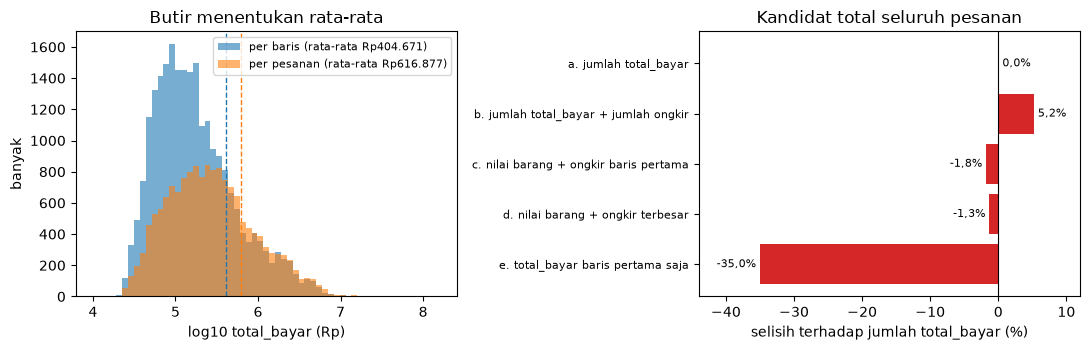

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tepi = np.linspace(4, 8.2, 60)
ax[0].hist(np.log10(b.total_bayar), bins=tepi, alpha=.6, label=f"per baris (rata-rata {rp(B['rata_baris'])})")
ax[0].hist(np.log10(pesanan.total_bayar), bins=tepi, alpha=.6, label=f"per pesanan (rata-rata {rp(B['rata_pesanan'])})")
for x_, w_ in [(B["rata_baris"], "C0"), (B["rata_pesanan"], "C1")]:
    ax[0].axvline(np.log10(x_), color=w_, ls="--", lw=1)
ax[0].set_xlabel("log10 total_bayar (Rp)"); ax[0].set_ylabel("banyak"); ax[0].legend(fontsize=8)
ax[0].set_title("Butir menentukan rata-rata")
warna = ["C2"] + ["C3"] * (len(kandidat) - 1)
ax[1].barh(list(kandidat.index)[::-1], kandidat.selisih_persen[::-1], color=warna[::-1])
for i, v_ in enumerate(kandidat.selisih_persen[::-1]):
    ax[1].text(v_ + (.6 if v_ >= 0 else -.6), i, f"{angka(v_)}%", va="center", ha="left" if v_ >= 0 else "right", fontsize=8)
ax[1].axvline(0, color="k", lw=.8); ax[1].set_xlim(-44, 12); ax[1].tick_params(axis="y", labelsize=8)
ax[1].set_xlabel("selisih terhadap jumlah total_bayar (%)"); ax[1].set_title("Kandidat total seluruh pesanan")
fig.tight_layout(); fig.savefig(OUT / "01_butir_pesanan.png", dpi=110); plt.show()

**Pembahasan A**

| Pertanyaan | Jawaban dari data |
|---|---|
| Butir `transaksi_m04` | **baris pesanan**: 24.000 baris = 15.744 pesanan (9.411 satu baris, 4.410 dua baris, 1.923 tiga baris) |
| Atribut pesanan (sama di semua baris) | `kanal`, `id_pelanggan`, `id_entitas`, `kota_tujuan`, `provinsi_tujuan`, `kurir`, `metode_bayar`, `status` |
| Atribut baris | `kode_produk`, `jumlah`, **`ongkir`** (berbeda pada 3.357 pesanan), `total_bayar`, `rating_ulasan` (2.434), `lama_kirim_hari` (81), `waktu_wib` (10) |
| Pembeli tamu | 411 baris = 268 pesanan tanpa `id_entitas` |

- **Waktu pesanan.** `waktu_wib` berbeda antarbaris pada 10 pesanan, dan **semuanya** karena sebagian
  barisnya `NaT` (waktu di luar masa operasi, Modul 4); selain itu tidak ada pesanan yang barisnya
  berbeda waktu. Aturan `min()` memberi waktu sah paling awal: 10 pesanan itu tertolong dan hanya
  **8 pesanan** (seluruh barisnya `NaT`) yang tetap tanpa waktu. Jalan pintas
  `drop_duplicates("id_pesanan")` mengambil baris pertama apa adanya: 11 pesanan tanpa waktu, 3 di
  antaranya sebenarnya punya waktu di baris lain.
- **Ongkir berbutir baris, bukan pesanan.** Identitas `total_bayar = jumlah × harga × (1 − diskon) +
  ongkir` cocok pada 23.977 dari 24.000 baris (22 baris berongkir isian median Modul 2 dan 1 baris
  ber-`jumlah` kosong tidak dapat diperiksa). Jadi `total_bayar` setiap baris **sudah memuat** ongkir
  baris itu. Bila ongkir adalah atribut pesanan yang diulang, ongkir akan sama di semua baris; faktanya
  hanya 2.976 dari 6.333 pesanan multi-baris yang ongkirnya sama.

| Kandidat "total seluruh pesanan" | Juta rupiah | Selisih |
|---|---:|---:|
| a. jumlah `total_bayar` | **9.712,10** | 0 |
| b. jumlah `total_bayar` + jumlah `ongkir` | 10.218,96 | **+5,22%** (ongkir Rp506,9 juta terhitung dua kali) |
| c. nilai barang + ongkir baris pertama | 9.536,05 | −1,81% (ongkir baris ke-2 dan ke-3 hilang) |
| d. nilai barang + ongkir terbesar | 9.582,38 | −1,34% |
| e. `total_bayar` baris pertama saja (`drop_duplicates`) | 6.310,31 | **−35,03%** |

- Hanya (a) yang direkonsiliasi. Kesalahan (b) dan (c) sama-sama lahir dari **menebak** butir ongkir
  tanpa memeriksanya; arahnya berlawanan, dan keduanya tidak menimbulkan galat.
- **Join yang menggandakan baris.** `kode_produk → kategori` adalah many-to-one (850 kode unik), jadi
  jumlah baris tetap 24.000. `id_toko → provinsi_toko` **bukan**: 166 dari 177 toko tercatat di lebih
  dari satu provinsi (atribut baris produk, catatan Modul 4). Join lewat `id_toko` menghasilkan
  **105.331 baris** dan "total" Rp42.356,8 juta, empat kali lipat, tanpa galat. `validate="many_to_one"`
  menghentikannya dengan `MergeError`.
- **Tabel pesanan** (`pesanan_m06.parquet`, 15.744 × 20): setiap kolom memakai fungsi agregasi yang
  dipilih dari temuan di atas, bukan dari kebiasaan: `first` untuk atribut pesanan, `min` untuk waktu,
  `sum` untuk ongkir dan total, `any` untuk bendera. 5.609 pesanan memuat lebih dari satu kategori;
  83 memuat pembelian grosir; 76 memuat produk yang tidak dikenal; 1 pesanan ber-`n_unit` kosong
  karena satu barisnya tidak punya `jumlah`. Empat `assert` membuktikan tidak ada baris dan rupiah
  yang hilang.
- Rata-rata `total_bayar` per **baris** Rp404.671; per **pesanan** Rp616.877. Butir menentukan
  rata-rata (grafik 01).

## Bagian B — Mengelompokkan dan merangkum: pembilang, penyebut, dan bobot

### B.1 Omzet dan status pesanan

In [50]:
ringkas_status = (pesanan.groupby("status")
                         .agg(pesanan=("id_pesanan", "size"), total_bayar=("total_bayar", "sum"))
                         .sort_values("pesanan", ascending=False))
ringkas_status["porsi_pesanan"] = ringkas_status.pesanan / ringkas_status.pesanan.sum()
ringkas_status["porsi_total"] = ringkas_status.total_bayar / ringkas_status.total_bayar.sum()

# Definisi omzet modul ini (naskah, studi kasus): total_bayar pesanan berstatus "selesai"
# yang waktu pesanannya sah. Definisi ditulis sekali, lalu dipakai di semua tabel.
selesai = pesanan[pesanan.status.eq("selesai") & pesanan.waktu_wib.notna()].copy()
OMZET, N_SELESAI = float(selesai.total_bayar.sum()), len(selesai)
print("pesanan selesai berwaktu sah:", N_SELESAI, "| omzet:", juta(OMZET))
ringkas_status.round(3)

pesanan selesai berwaktu sah: 12985 | omzet: 8.024,2 juta


,pesanan,total_bayar,porsi_pesanan,porsi_total
status,,,,
selesai,12992,8.029065e+09,0.825,0.827
diproses,1078,6.525167e+08,0.068,0.067
dibatalkan,1047,6.378558e+08,0.067,0.066
dikembalikan,627,3.926677e+08,0.040,0.040


In [51]:
B["omzet"], B["n_selesai"] = OMZET, N_SELESAI
B["total_semua_status"] = float(pesanan.total_bayar.sum())
B["inflasi_status_persen"] = 100 * (B["total_semua_status"] / OMZET - 1)
B["status_pesanan"] = ringkas_status.pesanan.to_dict()
tanpa_waktu = pesanan[pesanan.status.eq("selesai") & pesanan.waktu_wib.isna()]
B["selesai_tanpa_waktu"], B["selesai_tanpa_waktu_rp"] = len(tanpa_waktu), float(tanpa_waktu.total_bayar.sum())
B["omzet_definisi_baris"] = float(t4.total_bayar[t4.status.eq("selesai") & t4.waktu_wib.notna()].sum())
B["baris_terselamatkan"] = int((b.status.eq("selesai") & b.waktu_wib.isna() & b.waktu_pesanan.notna()).sum())
print(f"semua status {juta(B['total_semua_status'])} = {angka(B['inflasi_status_persen'])}% di atas omzet {juta(OMZET)}")
print(f"selesai tanpa waktu: {B['selesai_tanpa_waktu']} pesanan, {juta(B['selesai_tanpa_waktu_rp'], 2)}")
print(f"definisi dari baris (waktu per baris): {juta(B['omzet_definisi_baris'])}; selisih {juta(OMZET - B['omzet_definisi_baris'], 2)} "
      f"= {B['baris_terselamatkan']} baris ber-NaT pada pesanan yang baris lainnya berwaktu")

semua status 9.712,1 juta = 21,0% di atas omzet 8.024,2 juta
selesai tanpa waktu: 7 pesanan, 4,81 juta
definisi dari baris (waktu per baris): 8.022,2 juta; selisih 2,02 juta = 9 baris ber-NaT pada pesanan yang baris lainnya berwaktu


### B.2 Rata-rata nilai pesanan: penyebut yang mana?

In [52]:
print("rata-rata total_bayar per baris transaksi:", rp(b.total_bayar.mean()))

aov_prov = (selesai.groupby("provinsi_tujuan")
                   .agg(pesanan=("id_pesanan", "size"),          # agregasi bernama: kolom_baru=(kolom, fungsi)
                        omzet=("total_bayar", "sum"),
                        median_pesanan=("total_bayar", "median")))
aov_prov["aov"] = aov_prov.omzet / aov_prov.pesanan              # rasio = jumlah pembilang / jumlah penyebut
aov_prov.sort_values("aov", ascending=False).round(0)

rata-rata total_bayar per baris transaksi: Rp404.671


,pesanan,omzet,median_pesanan,aov
provinsi_tujuan,,,,
Jambi,774,5.536611e+08,256500.0,715324.0
Sumatera Barat,1268,8.130468e+08,249250.0,641204.0
Kepulauan Riau,945,5.973174e+08,253800.0,632082.0
Lampung,2262,1.425590e+09,252400.0,630234.0
Sumatera Utara,2623,1.626591e+09,258650.0,620126.0
Aceh,888,5.373569e+08,245825.0,605132.0
Bengkulu,640,3.851061e+08,225500.0,601728.0
Kepulauan Bangka Belitung,519,3.105672e+08,248500.0,598395.0
Sumatera Selatan,1787,1.040172e+09,246000.0,582077.0


In [53]:
bs = b[b.status.eq("selesai") & b.waktu_pesanan.notna()]       # baris milik pesanan selesai berwaktu sah
assert np.isclose(bs.total_bayar.sum(), OMZET)
AOV = OMZET / N_SELESAI
B["aov"], B["rata_baris_selesai"], B["median_pesanan"] = AOV, float(bs.total_bayar.mean()), float(selesai.total_bayar.median())
B["n_entitas_selesai"] = int(selesai.id_entitas.nunique())
B["omzet_per_pelanggan"] = float(selesai.total_bayar[selesai.id_entitas.notna()].sum() / B["n_entitas_selesai"])
B["rata_dari_rata"] = float(aov_prov.aov.mean())
B["rata_tertimbang"] = float(np.average(aov_prov.aov, weights=aov_prov.pesanan))
assert np.isclose(B["rata_tertimbang"], AOV)
B["aov_min"] = (aov_prov.aov.idxmin(), float(aov_prov.aov.min()))
B["aov_maks"] = (aov_prov.aov.idxmax(), float(aov_prov.aov.max()))
tanpa_grosir = selesai[~selesai.ada_grosir]
B["aov_tanpa_grosir"] = float(tanpa_grosir.total_bayar.mean())
B["grosir_selesai"] = int(selesai.ada_grosir.sum())
B["grosir_omzet"] = float(selesai.total_bayar[selesai.ada_grosir].sum())

aov_prov["pangsa_omzet"] = aov_prov.omzet / OMZET
aov_provinsi = aov_prov.rename_axis("provinsi").reset_index()[["provinsi", "pesanan", "omzet", "aov", "median_pesanan", "pangsa_omzet"]]
assert aov_provinsi.pesanan.sum() == N_SELESAI and np.isclose(aov_provinsi.omzet.sum(), OMZET)
aov_provinsi.to_csv(OUT / "aov_provinsi_m06.csv", index=False)
print(f"per baris {rp(B['rata_baris_selesai'])} | per pesanan (AOV) {rp(AOV)} | per pelanggan {rp(B['omzet_per_pelanggan'])} "
      f"({B['n_entitas_selesai']} entitas) | median pesanan {rp(B['median_pesanan'])}")
print(f"rata-rata dari 10 AOV provinsi {rp(B['rata_dari_rata'])} vs AOV {rp(AOV)}; tertimbang pesanan {rp(B['rata_tertimbang'])}")
print(f"AOV terendah {B['aov_min'][0]} {rp(B['aov_min'][1])}, tertinggi {B['aov_maks'][0]} {rp(B['aov_maks'][1])}")
print(f"pesanan memuat grosir {B['grosir_selesai']} ({juta(B['grosir_omzet'])} = {angka(100 * B['grosir_omzet'] / OMZET)}% omzet); "
      f"AOV tanpa grosir {rp(B['aov_tanpa_grosir'])}")

per baris Rp404.734 | per pesanan (AOV) Rp617.963 | per pelanggan Rp1.753.952 (4491 entitas) | median pesanan Rp250.375
rata-rata dari 10 AOV provinsi Rp620.085 vs AOV Rp617.963; tertimbang pesanan Rp617.963
AOV terendah Riau Rp574.543, tertinggi Jambi Rp715.324
pesanan memuat grosir 64 (628,4 juta = 7,8% omzet); AOV tanpa grosir Rp572.389


### B.3 `agg` meringkas, `transform` menyiarkan

In [54]:
# agg: satu baris per kelompok. transform: hasil kelompok disiarkan kembali ke setiap baris asal.
per_pelanggan = (selesai.groupby("id_entitas")
                        .agg(pesanan=("id_pesanan", "size"), omzet=("total_bayar", "sum"),
                             pertama=("waktu_wib", "min")))
selesai["omzet_pelanggan"] = selesai.groupby("id_entitas").total_bayar.transform("sum")
selesai["pesanan_pelanggan"] = selesai.groupby("id_entitas").id_pesanan.transform("size")
selesai["pangsa_dalam_bulan"] = selesai.total_bayar / selesai.groupby("bulan").total_bayar.transform("sum")
print("agg      :", per_pelanggan.shape, "(satu baris per pelanggan)")
print("transform:", selesai.shape, "(tetap satu baris per pesanan)")
selesai[["id_pesanan", "id_entitas", "total_bayar", "omzet_pelanggan", "pesanan_pelanggan", "pangsa_dalam_bulan"]].head(4)

agg      : (4491, 3) (satu baris per pelanggan)
transform: (12985, 23) (tetap satu baris per pesanan)


,id_pesanan,id_entitas,total_bayar,omzet_pelanggan,pesanan_pelanggan,pangsa_dalam_bulan
1,LS-2025-009886,E-02910,6982200.0,7722150.0,2.0,0.021156
2,LS-2025-005990,E-03232,32300.0,727400.0,4.0,0.000098
3,LS-2025-002789,E-01301,185000.0,1672575.0,3.0,0.000561
4,LS-2025-015595,E-01076,11691400.0,11691400.0,1.0,0.035425


In [55]:
B["selesai_tamu"] = int(selesai.omzet_pelanggan.isna().sum())
B["selesai_tamu_rp"] = float(selesai.total_bayar[selesai.id_entitas.isna()].sum())
assert np.isclose(per_pelanggan.omzet.sum() + B["selesai_tamu_rp"], OMZET)
ulang = per_pelanggan.pesanan.gt(1)
B["pelanggan_ulang_persen"] = 100 * float(ulang.mean())
B["omzet_ulang_persen"] = 100 * float(per_pelanggan.omzet[ulang].sum() / per_pelanggan.omzet.sum())
per_id = selesai.groupby("id_pelanggan").agg(pesanan=("id_pesanan", "size"), omzet=("total_bayar", "sum"))
B["n_id_pelanggan"] = len(per_id)
B["sekali_id"], B["sekali_entitas"] = int(per_id.pesanan.eq(1).sum()), int(per_pelanggan.pesanan.eq(1).sum())
B["aov_rata_pelanggan"] = float((per_pelanggan.omzet / per_pelanggan.pesanan).mean())
B["aov_terdaftar"] = float(per_pelanggan.omzet.sum() / per_pelanggan.pesanan.sum())
B["pesanan_maks_pelanggan"] = int(per_pelanggan.pesanan.max())
print(f"pesanan selesai pembeli tamu: {B['selesai_tamu']} ({juta(B['selesai_tamu_rp'])}) -> kunci kosong dibuang groupby")
print(f"pelanggan berulang {angka(B['pelanggan_ulang_persen'])}% menyumbang {angka(B['omzet_ulang_persen'])}% omzet terdaftar; "
      f"maksimum {B['pesanan_maks_pelanggan']} pesanan")
print(f"kunci id_pelanggan: {B['n_id_pelanggan']} 'pelanggan' (entitas {B['n_entitas_selesai']}); "
      f"sekali beli {B['sekali_id']} vs {B['sekali_entitas']}")
print(f"rata-rata AOV per pelanggan {rp(B['aov_rata_pelanggan'])} vs AOV pesanan terdaftar {rp(B['aov_terdaftar'])}")

pesanan selesai pembeli tamu: 213 (147,2 juta) -> kunci kosong dibuang groupby
pelanggan berulang 76,7% menyumbang 92,1% omzet terdaftar; maksimum 13 pesanan
kunci id_pelanggan: 5099 'pelanggan' (entitas 4491); sekali beli 1378 vs 1045
rata-rata AOV per pelanggan Rp612.104 vs AOV pesanan terdaftar Rp616.740


### B.4 Rata-rata tertimbang

In [56]:
bs = b[b.status.eq("selesai") & b.waktu_pesanan.notna()]       # baris milik pesanan selesai berwaktu sah
dk = (bs.groupby("kategori")
        .agg(baris=("baris_ke", "size"), unit=("jumlah", "sum"), nilai_kotor=("nilai_kotor", "sum"),
             diskon_rata_baris=("diskon_persen", "mean"), harga_rata_baris=("harga_satuan", "mean")))
print("baris pada tabel:", int(dk.baris.sum()), "| baris pesanan selesai:", len(bs))
dk.round(2)

baris pada tabel: 19767 | baris pesanan selesai: 19826


,baris,unit,nilai_kotor,diskon_rata_baris,harga_rata_baris
kategori,,,,,
Kain Tenun,1467,3503,3.159164e+09,9.29,907721.20
Kerajinan,2712,6416,2.253720e+09,9.26,353617.63
Kopi,3644,13106,1.413063e+09,9.29,109811.88
Makanan Ringan,3714,8833,3.057055e+08,9.32,34731.96
Olahan Ikan,2644,6265,4.282235e+08,9.42,68820.35
Rempah,3069,11134,5.233150e+08,9.42,49602.15
Sayur dan Buah Segar,2517,5995,2.688230e+08,9.24,44838.50


In [57]:
TAK_DIKENAL = "Tidak dikenal"
B["kategori_kosong_baris"] = int(bs.kategori.isna().sum())
B["kategori_kosong_semua"] = int(b.kategori.isna().sum())
B["kategori_kosong_rp"] = float(bs.total_bayar[bs.kategori.isna()].sum())
B["dk_baris_awal"] = int(dk.baris.sum())
b["kategori"] = b.kategori.fillna(TAK_DIKENAL)                 # keputusan: label tersendiri, baris tidak dibuang
bs = b[b.status.eq("selesai") & b.waktu_pesanan.notna()]

bs = bs.assign(rp_diskon=bs.diskon_persen * bs.nilai_kotor)
dk = (bs.groupby("kategori")
        .agg(baris=("baris_ke", "size"), unit=("jumlah", "sum"), nilai_kotor=("nilai_kotor", "sum"),
             rp_diskon=("rp_diskon", "sum"), diskon_rata_baris=("diskon_persen", "mean"),
             harga_rata_baris=("harga_satuan", "mean")))
dk["diskon_efektif"] = dk.rp_diskon / dk.nilai_kotor            # rata-rata tertimbang nilai kotor
dk["harga_per_unit"] = dk.nilai_kotor / dk.unit.astype(float)   # rata-rata tertimbang unit
diskon_kategori = dk.reset_index()[["kategori", "baris", "unit", "nilai_kotor", "diskon_rata_baris",
                                    "diskon_efektif", "harga_rata_baris", "harga_per_unit"]]
assert diskon_kategori.baris.sum() == len(bs)
diskon_kategori.to_csv(OUT / "diskon_kategori_m06.csv", index=False)

beda = (dk.diskon_efektif - dk.diskon_rata_baris).drop(TAK_DIKENAL)
B["diskon_beda_kategori"] = beda.abs().idxmax()
B["diskon_beda"] = (float(dk.diskon_rata_baris[B["diskon_beda_kategori"]]), float(dk.diskon_efektif[B["diskon_beda_kategori"]]))
gr = bs[bs.pembelian_grosir]
B["grosir_baris"] = len(gr)
B["grosir_kategori"] = gr.kategori.value_counts().to_dict()
B["grosir_diskon"] = float(gr.diskon_persen.mean())
B["grosir_unit_persen"] = {k: 100 * float(gr.jumlah[gr.kategori.eq(k)].sum() / dk.unit[k]) for k in B["grosir_kategori"]}
tujuh = dk.drop(TAK_DIKENAL)
B["harga_rata_dari_rata"] = float(tujuh.harga_rata_baris.mean())
B["harga_rata_semua"] = float(bs.harga_satuan[bs.kategori.ne(TAK_DIKENAL)].mean())
B["harga_per_unit_semua"] = float(tujuh.nilai_kotor.sum() / tujuh.unit.astype(float).sum())
B["diskon_rata_semua"] = float(bs.diskon_persen.mean())
B["diskon_efektif_semua"] = float(dk.rp_diskon.sum() / dk.nilai_kotor.sum())
print(f"kategori kosong: {B['kategori_kosong_baris']} baris selesai ({juta(B['kategori_kosong_rp'], 2)}), "
      f"{B['kategori_kosong_semua']} baris di semua status; tabel awal hanya {B['dk_baris_awal']} dari {len(bs)} baris")
print(f"diskon: rata-rata per baris {angka(B['diskon_rata_semua'], 2)}% vs efektif {angka(B['diskon_efektif_semua'], 2)}%; "
      f"paling berbeda {B['diskon_beda_kategori']} {angka(B['diskon_beda'][0], 2)}% -> {angka(B['diskon_beda'][1], 2)}%")
porsi_unit = {k: round(v, 1) for k, v in B["grosir_unit_persen"].items()}
print(f"grosir {B['grosir_baris']} baris {B['grosir_kategori']}, diskon rata-rata {angka(B['grosir_diskon'], 2)}%, "
      f"porsi unit kategori (%) {porsi_unit}")
print(f"harga: rata-rata dari 7 rata-rata {rp(B['harga_rata_dari_rata'])} | rata-rata seluruh baris {rp(B['harga_rata_semua'])} | "
      f"per unit terjual {rp(B['harga_per_unit_semua'])}")
diskon_kategori.round(2)

kategori kosong: 59 baris selesai (18,18 juta), 76 baris di semua status; tabel awal hanya 19767 dari 19826 baris
diskon: rata-rata per baris 9,32% vs efektif 9,14%; paling berbeda Rempah 9,42% -> 8,50%
grosir 64 baris {'Kopi': 34, 'Rempah': 30}, diskon rata-rata 9,14%, porsi unit kategori (%) {'Kopi': 34.3, 'Rempah': 35.9}
harga: rata-rata dari 7 rata-rata Rp224.163 | rata-rata seluruh baris Rp165.267 | per unit terjual Rp151.162


,kategori,baris,unit,nilai_kotor,diskon_rata_baris,diskon_efektif,harga_rata_baris,harga_per_unit
0,Kain Tenun,1467,3503,3.159164e+09,9.29,9.08,907721.20,901845.28
1,Kerajinan,2712,6416,2.253720e+09,9.26,9.26,353617.63,351265.51
2,Kopi,3644,13106,1.413063e+09,9.29,9.10,109811.88,107818.02
3,Makanan Ringan,3714,8833,3.057055e+08,9.32,9.36,34731.96,34609.48
4,Olahan Ikan,2644,6265,4.282235e+08,9.42,9.68,68820.35,68351.72
5,Rempah,3069,11134,5.233150e+08,9.42,8.50,49602.15,47001.53
6,Sayur dan Buah Segar,2517,5995,2.688230e+08,9.24,9.39,44838.50,44841.20
7,Tidak dikenal,59,141,1.832000e+07,8.73,7.88,120211.86,129929.08


**Pembahasan B**

- **Definisi omzet.** Semua status dijumlah: Rp9.712,1 juta. Pesanan `selesai` berwaktu sah: 12.985
  pesanan, **Rp8.024,2 juta**. Memasukkan pesanan dibatalkan (1.047), dikembalikan (627), dan diproses
  (1.078) menggelembungkan "omzet" **21,0%**. Tujuh pesanan selesai (Rp4,81 juta) keluar karena tidak
  punya waktu: tetap ada di `pesanan_m06`, tetapi tidak dapat ditempatkan pada bulan mana pun.
- Definisi yang sama dihitung **dari baris** (waktu per baris tidak kosong) memberi Rp8.022,2 juta:
  9 baris ber-`NaT` pada pesanan yang baris lainnya berwaktu ikut terbuang (Rp2,02 juta). Pesanan
  adalah satu kejadian; waktunya ditetapkan pada butir pesanan (A.2), lalu disiarkan ke baris.

| "Rata-rata nilai belanja" pesanan selesai | Nilai | Pembilang / penyebut |
|---|---:|---|
| per baris (`mean()` pada tabel baris) | Rp404.734 | omzet / 19.826 baris |
| per pesanan (AOV) | **Rp617.963** | omzet / 12.985 pesanan |
| median pesanan | Rp250.375 | separuh pesanan di bawah nilai ini |
| per pelanggan | Rp1.753.952 | omzet pelanggan terdaftar / 4.491 entitas |

- `mean()` pada kolom `total_bayar` tabel baris **bukan** AOV: penyebutnya baris, hasilnya 34,5% lebih
  kecil. Ketiganya benar untuk pertanyaan yang berbeda; kesalahannya adalah memberi nama yang salah.
- **AOV dua setengah kali median.** 64 pesanan selesai memuat pembelian grosir (sah, Modul 3) dan
  menyumbang Rp628,4 juta = 7,8% omzet; tanpa mereka AOV Rp572.389. AOV dan median dilaporkan bersama.
- **Rata-rata dari rata-rata.** Rata-rata sederhana sepuluh AOV provinsi Rp620.085, bukan Rp617.963:
  ia memberi bobot sama pada Kepulauan Bangka Belitung dan Sumatera Utara. Ditimbang banyak pesanan,
  hasilnya tepat Rp617.963. Di sini selisihnya kecil (0,34%) karena AOV antarprovinsi mirip
  (Rp574.543 Riau sampai Rp715.324 Jambi); B.4 memperlihatkan kasus yang selisihnya besar.
- **`transform` dan kunci kosong.** 213 pesanan selesai pembeli tamu (Rp147,2 juta) mendapat
  `omzet_pelanggan` kosong: `groupby` membuang kunci `NaN`. `per_pelanggan.omzet.sum()` karena itu
  **bukan** omzet; selisihnya tepat omzet pembeli tamu. 76,7% pelanggan memesan lebih dari sekali
  dan menyumbang 92,1% omzet pelanggan terdaftar.
- **Kunci pelanggan.** Dengan `id_pelanggan`, "pelanggan" menjadi 5.099 (seharusnya 4.491 entitas)
  dan "sekali beli" 1.378 (seharusnya 1.045): orang yang memakai web dan aplikasi terhitung dua kali.
- **Baris tanpa kategori.** Tabel `groupby("kategori")` hanya memuat 19.767 dari 19.826 baris: 59
  baris selesai (76 di semua status, Rp18,18 juta pada pesanan selesai) berkode produk di luar katalog
  sehingga `kategori`-nya `NaN` dan **dibuang diam-diam**. Keputusan: label `"Tidak dikenal"`; barisnya
  nyata dan ikut omzet (K-06-006).
- **Rata-rata tertimbang.** Diskon rata-rata per baris 9,32%; diskon efektif (rupiah diskon / nilai
  kotor) 9,14%. Paling berbeda **Rempah: 9,42% → 8,50%**. Penyebabnya 64 baris grosir (Kopi 34,
  Rempah 30): hanya 0,3% baris, tetapi 34,3% unit Kopi dan 35,9% unit Rempah.
- **Kasus besar rata-rata dari rata-rata.** Rata-rata harga satuan tujuh kategori Rp224.163; rata-rata
  harga seluruh baris Rp165.267 (**35,6% lebih rendah**); harga per unit terjual Rp151.162. Kain Tenun
  (7,4% baris, harga sekitar Rp900 ribu) mendapat bobot sepertujuh pada rata-rata pertama.

## Bagian C — Mengubah bentuk: lebar, panjang, dan tabel yang lengkap

### C.1 `pivot_table`: provinsi × bulan

In [58]:
pv_omzet = selesai.pivot_table(index="provinsi_tujuan", columns="bulan", values="total_bayar", aggfunc="sum")
pv_pesanan = selesai.pivot_table(index="provinsi_tujuan", columns="bulan", values="id_pesanan", aggfunc="count")
print(pv_omzet.shape, "| sel kosong:", int(pv_omzet.isna().sum().sum()))
(pv_omzet / 1e6).round(1).iloc[:, -6:]

(10, 18) | sel kosong: 0


bulan,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06
provinsi_tujuan,,,,,,
Aceh,43.2,46.4,15.9,42.5,42.1,34.9
Bengkulu,25.2,15.3,31.9,21.2,25.9,15.6
Jambi,18.1,31.8,52.1,25.1,40.3,35.9
Kepulauan Bangka Belitung,21.7,14.6,13.2,21.2,13.4,15.7
Kepulauan Riau,39.7,19.6,56.8,37.7,23.0,29.5
Lampung,103.5,92.4,121.2,63.1,116.2,92.0
Riau,38.2,43.4,72.3,63.0,44.7,63.7
Sumatera Barat,48.6,31.4,74.9,54.7,55.8,43.1
Sumatera Selatan,80.9,67.9,67.6,71.7,57.5,65.3


In [59]:
assert np.isclose(pv_omzet.to_numpy().sum(), OMZET) and pv_pesanan.to_numpy().sum() == N_SELESAI
dengan_margin = selesai.pivot_table(index="provinsi_tujuan", columns="bulan", values="total_bayar",
                                    aggfunc="sum", margins=True, margins_name="Semua")
assert np.isclose(dengan_margin.loc["Semua", "Semua"], OMZET)
pv_salah = bs.pivot_table(index="provinsi_tujuan", columns="bulan", values="id_pesanan", aggfunc="count")
pv_benar = bs.pivot_table(index="provinsi_tujuan", columns="bulan", values="id_pesanan", aggfunc="nunique")
assert pv_benar.equals(pv_pesanan)
B["pivot_bentuk"] = pv_omzet.shape
B["pivot_count_baris"] = int(pv_salah.to_numpy().sum())
pangsa = pv_omzet / pv_omzet.sum()
geser = (pangsa.iloc[:, -6:].mean(axis=1) - pangsa.iloc[:, :6].mean(axis=1)) * 100
B["pangsa_naik"], B["pangsa_turun"] = (geser.idxmax(), float(geser.max())), (geser.idxmin(), float(geser.min()))
B["pangsa_terbesar"] = (pv_omzet.sum(axis=1).idxmax(), 100 * float(pv_omzet.sum(axis=1).max() / OMZET))
B["bulan_terbesar"] = (pv_omzet.sum().idxmax(), float(pv_omzet.sum().max()))
B["bulan_terkecil"] = (pv_omzet.sum().idxmin(), float(pv_omzet.sum().min()))

pivot_omzet = pv_omzet.rename_axis(index="provinsi", columns=None).reset_index()
pivot_omzet.to_csv(OUT / "pivot_omzet_provinsi_m06.csv", index=False)
print(f"pivot {B['pivot_bentuk']} direkonsiliasi: {juta(OMZET)}, {N_SELESAI} pesanan")
print(f"aggfunc='count' pada baris: {B['pivot_count_baris']} 'pesanan' (seharusnya {N_SELESAI}); nunique benar")
print(f"pangsa terbesar {B['pangsa_terbesar'][0]} {angka(B['pangsa_terbesar'][1])}%; "
      f"naik {B['pangsa_naik'][0]} {angka(B['pangsa_naik'][1], 2)} poin, turun {B['pangsa_turun'][0]} {angka(B['pangsa_turun'][1], 2)} poin")
print(f"bulan omzet terbesar {B['bulan_terbesar'][0]} {juta(B['bulan_terbesar'][1])}, terkecil {B['bulan_terkecil'][0]} {juta(B['bulan_terkecil'][1])}")

pivot (10, 18) direkonsiliasi: 8.024,2 juta, 12985 pesanan
aggfunc='count' pada baris: 19826 'pesanan' (seharusnya 12985); nunique benar
pangsa terbesar Sumatera Utara 20,3%; naik Riau 1,95 poin, turun Kepulauan Riau -2,21 poin
bulan omzet terbesar 2026-03 595,0 juta, terkecil 2025-02 328,7 juta


### C.2 `melt`: kembali ke bentuk panjang

In [60]:
panjang = pv_omzet.reset_index().melt(id_vars="provinsi_tujuan", var_name="bulan", value_name="omzet")
langsung = selesai.groupby(["provinsi_tujuan", "bulan"], as_index=False).total_bayar.sum()
print("melt dari pivot :", panjang.shape, list(panjang.columns))
print("groupby langsung:", langsung.shape, list(langsung.columns))
panjang.head(3)

melt dari pivot : (180, 3) ['provinsi_tujuan', 'bulan', 'omzet']
groupby langsung: (180, 3) ['provinsi_tujuan', 'bulan', 'total_bayar']


,provinsi_tujuan,bulan,omzet
0,Aceh,2025-01,25173000.0
1,Bengkulu,2025-01,35263700.0
2,Jambi,2025-01,19620400.0


In [61]:
a_ = panjang.sort_values(["provinsi_tujuan", "bulan"]).reset_index(drop=True)
b_ = langsung.rename(columns={"total_bayar": "omzet"}).sort_values(["provinsi_tujuan", "bulan"]).reset_index(drop=True)
B["melt_equals_mentah"] = bool(panjang.equals(langsung))
B["melt_equals_rapi"] = bool(a_.equals(b_))
kembali = panjang.pivot(index="provinsi_tujuan", columns="bulan", values="omzet")
B["pivot_kembali_equals"] = bool(kembali.equals(pv_omzet))
try:
    bs.pivot(index="provinsi_tujuan", columns="bulan", values="total_bayar")
except ValueError as e:
    B["pivot_galat"] = str(e)
print("equals tanpa dirapikan:", B["melt_equals_mentah"], "| setelah nama kolom dan urutan disamakan:", B["melt_equals_rapi"])
print("pivot(melt(pivot)) equals pivot:", B["pivot_kembali_equals"])
print(".pivot() pada tabel baris:", B.get("pivot_galat"))

equals tanpa dirapikan: False | setelah nama kolom dan urutan disamakan: True
pivot(melt(pivot)) equals pivot: True
.pivot() pada tabel baris: Index contains duplicate entries, cannot reshape


### C.3 Sel yang kosong dan tabel yang lengkap

In [62]:
BULAN = sorted(selesai.bulan.unique())
PROVINSI = sorted(selesai.provinsi_tujuan.unique())
KATEGORI = sorted(bs.kategori.unique())

sel = (bs.rename(columns={"provinsi_tujuan": "provinsi"})
         .groupby(["bulan", "provinsi", "kategori"])
         .agg(omzet=("total_bayar", "sum"), pesanan=("id_pesanan", "nunique"),
              baris=("baris_ke", "size"), unit=("jumlah", "sum")))
print("sel terisi:", len(sel), "dari", len(BULAN) * len(PROVINSI) * len(KATEGORI), "kombinasi bulan x provinsi x kategori")

sel terisi: 1309 dari 1440 kombinasi bulan x provinsi x kategori


In [63]:
kisi = pd.MultiIndex.from_product([BULAN, PROVINSI, KATEGORI], names=["bulan", "provinsi", "kategori"])
hilang = kisi.difference(sel.index).to_frame(index=False)
B["sel_terisi"], B["sel_semua"] = len(sel), len(kisi)
B["sel_hilang_tak_dikenal"] = int(hilang.kategori.eq(TAK_DIKENAL).sum())
B["sel_hilang_lain"] = hilang[hilang.kategori.ne(TAK_DIKENAL)].to_dict("records")

penuh = sel.reindex(kisi, fill_value=0)          # jumlah dan cacah: tidak ada transaksi = 0, bukan "tidak diketahui"
contoh = hilang[hilang.kategori.ne(TAK_DIKENAL)].iloc[0] if B["sel_hilang_lain"] else hilang.iloc[0]
pilih = lambda t_: t_.xs((contoh.provinsi, contoh.kategori), level=["provinsi", "kategori"]).omzet   # noqa: E731
B["contoh_sel"] = (contoh.provinsi, contoh.kategori, contoh.bulan)
B["contoh_rata_apa_adanya"], B["contoh_bulan_ada"] = float(pilih(sel).mean()), int(len(pilih(sel)))
B["contoh_rata_lengkap"] = float(pilih(penuh).mean())
tk = sel.xs(TAK_DIKENAL, level="kategori").omzet.groupby("provinsi").agg(["mean", "size", "sum"])
B["tak_dikenal_rata_apa_adanya"] = float(tk["mean"].mean())
B["tak_dikenal_rata_lengkap"] = float(penuh.xs(TAK_DIKENAL, level="kategori").omzet.groupby("provinsi").mean().mean())

ringkasan = (penuh.astype("float64").reset_index()
                  .melt(id_vars=["bulan", "provinsi", "kategori"], var_name="metrik", value_name="nilai"))
assert len(ringkasan) == len(kisi) * 4 and ringkasan.nilai.notna().all()
total_metrik = ringkasan.groupby("metrik").nilai.sum()
assert np.isclose(total_metrik["omzet"], OMZET) and total_metrik["baris"] == len(bs)
B["ringkasan_baris"] = len(ringkasan)
B["pesanan_dijumlah_kategori"] = int(total_metrik["pesanan"])
B["unit_selesai"] = int(total_metrik["unit"])
ringkasan.to_parquet(OUT / "ringkasan_bulanan_m06.parquet", index=False)
print(f"sel terisi {B['sel_terisi']} dari {B['sel_semua']}; hilang: {B['sel_hilang_tak_dikenal']} sel '{TAK_DIKENAL}' "
      f"dan {len(B['sel_hilang_lain'])} lainnya {B['sel_hilang_lain']}")
print(f"contoh {B['contoh_sel'][0]} x {B['contoh_sel'][1]}: rata-rata {B['contoh_bulan_ada']} bulan yang ada {rp(B['contoh_rata_apa_adanya'])} "
      f"vs 18 bulan {rp(B['contoh_rata_lengkap'])}")
print(f"'{TAK_DIKENAL}' rata-rata omzet bulanan per provinsi: apa adanya {rp(B['tak_dikenal_rata_apa_adanya'])} vs lengkap {rp(B['tak_dikenal_rata_lengkap'])}")
print(f"ringkasan {ringkasan.shape}: omzet {juta(total_metrik['omzet'])} cocok, baris {int(total_metrik['baris'])} cocok, "
      f"pesanan dijumlah lintas kategori {B['pesanan_dijumlah_kategori']} (pesanan selesai {N_SELESAI})")
ringkasan.head(4)

sel terisi 1309 dari 1440; hilang: 130 sel 'Tidak dikenal' dan 1 lainnya [{'bulan': '2025-07', 'provinsi': 'Kepulauan Riau', 'kategori': 'Kain Tenun'}]
contoh Kepulauan Riau x Kain Tenun: rata-rata 17 bulan yang ada Rp12.202.304 vs 18 bulan Rp11.524.399
'Tidak dikenal' rata-rata omzet bulanan per provinsi: apa adanya Rp350.156 vs lengkap Rp101.017
ringkasan (5760, 5): omzet 8.024,2 juta cocok, baris 19826 cocok, pesanan dijumlah lintas kategori 18583 (pesanan selesai 12985)


,bulan,provinsi,kategori,metrik,nilai
0,2025-01,Aceh,Kain Tenun,omzet,11303700.0
1,2025-01,Aceh,Kerajinan,omzet,6096775.0
2,2025-01,Aceh,Kopi,omzet,3330850.0
3,2025-01,Aceh,Makanan Ringan,omzet,971025.0


### C.4 `crosstab`, kolom bertingkat, dan grafik dari dua bentuk

In [64]:
ct = pd.crosstab(bs.kategori, bs.kanal, values=bs.total_bayar, aggfunc="sum", margins=True, margins_name="Semua")
print((ct / 1e6).round(1))
pd.crosstab(bs.kategori, bs.kanal, normalize="columns").round(3)      # cacah BARIS, dinormalkan per kolom

kanal                    app     web   Semua
kategori                                    
Kain Tenun            1310.8  1588.8  2899.7
Kerajinan              976.4  1141.0  2117.4
Kopi                   610.3   745.1  1355.4
Makanan Ringan         151.9   183.3   335.2
Olahan Ikan            195.6   234.5   430.1
Rempah                 223.2   310.4   533.6
Sayur dan Buah Segar   151.5   183.1   334.7
Tidak dikenal           10.8     7.3    18.2
Semua                 3630.7  4393.5  8024.2


kanal,app,web
kategori,,
Kain Tenun,0.074,0.074
Kerajinan,0.139,0.135
Kopi,0.186,0.182
Makanan Ringan,0.185,0.189
Olahan Ikan,0.132,0.135
Rempah,0.152,0.157
Sayur dan Buah Segar,0.127,0.127
Tidak dikenal,0.004,0.002


In [65]:
kk = (bs.groupby(["kategori", "kanal"])
        .agg(baris=("baris_ke", "size"), pesanan=("id_pesanan", "nunique"), omzet=("total_bayar", "sum"))
        .unstack("kanal"))
kk.columns = [f"{metrik}_{kanal}" for metrik, kanal in kk.columns]        # kolom bertingkat -> nama datar
for kanal in ["app", "web"]:
    kk[f"pangsa_omzet_{kanal}"] = kk[f"omzet_{kanal}"] / kk[f"omzet_{kanal}"].sum()
kategori_kanal = kk.reset_index()
assert np.isclose(kategori_kanal.omzet_app.sum() + kategori_kanal.omzet_web.sum(), OMZET)
kategori_kanal.to_csv(OUT / "kategori_kanal_m06.csv", index=False)
B["pesanan_per_kanal"] = selesai.kanal.value_counts().to_dict()
B["pesanan_kategori_kanal"] = {k: int(kk[f"pesanan_{k}"].sum()) for k in ["app", "web"]}
selisih_pangsa = (kk.pangsa_omzet_app - kk.pangsa_omzet_web).drop(TAK_DIKENAL) * 100
B["pangsa_kanal_beda"] = (selisih_pangsa.abs().idxmax(), float(selisih_pangsa[selisih_pangsa.abs().idxmax()]))
B["omzet_kanal"] = selesai.groupby("kanal").total_bayar.sum().to_dict()
B["kain_pangsa_baris"] = 100 * float(bs.kategori.eq("Kain Tenun").mean())
B["kain_pangsa_omzet"] = 100 * float(bs.total_bayar[bs.kategori.eq("Kain Tenun")].sum() / OMZET)
print(f"pesanan per kanal {B['pesanan_per_kanal']}; dijumlah lintas kategori {B['pesanan_kategori_kanal']}")
print(f"pangsa kategori paling berbeda antarkanal: {B['pangsa_kanal_beda'][0]} {angka(B['pangsa_kanal_beda'][1], 2)} poin (app - web)")
print(f"Kain Tenun: {angka(B['kain_pangsa_baris'])}% baris, {angka(B['kain_pangsa_omzet'])}% omzet")
kategori_kanal.round(3)

pesanan per kanal {'web': 7102, 'app': 5883}; dijumlah lintas kategori {'app': 8508, 'web': 10075}
pangsa kategori paling berbeda antarkanal: Kerajinan 0,92 poin (app - web)
Kain Tenun: 7,4% baris, 36,1% omzet


,kategori,baris_app,baris_web,pesanan_app,pesanan_web,omzet_app,omzet_web,pangsa_omzet_app,pangsa_omzet_web
0,Kain Tenun,673,794,654,764,1.310839e+09,1.588836e+09,0.361,0.362
1,Kerajinan,1257,1455,1208,1363,9.764215e+08,1.140988e+09,0.269,0.260
2,Kopi,1689,1955,1559,1800,6.102909e+08,7.450793e+08,0.168,0.170
3,Makanan Ringan,1680,2034,1541,1885,1.519418e+08,1.832565e+08,0.042,0.042
4,Olahan Ikan,1193,1451,1130,1373,1.955972e+08,2.345230e+08,0.054,0.053
5,Rempah,1377,1692,1292,1583,2.232380e+08,3.103940e+08,0.061,0.071
6,Sayur dan Buah Segar,1154,1363,1090,1282,1.515442e+08,1.831174e+08,0.042,0.042
7,Tidak dikenal,34,25,34,25,1.084595e+07,7.337150e+06,0.003,0.002


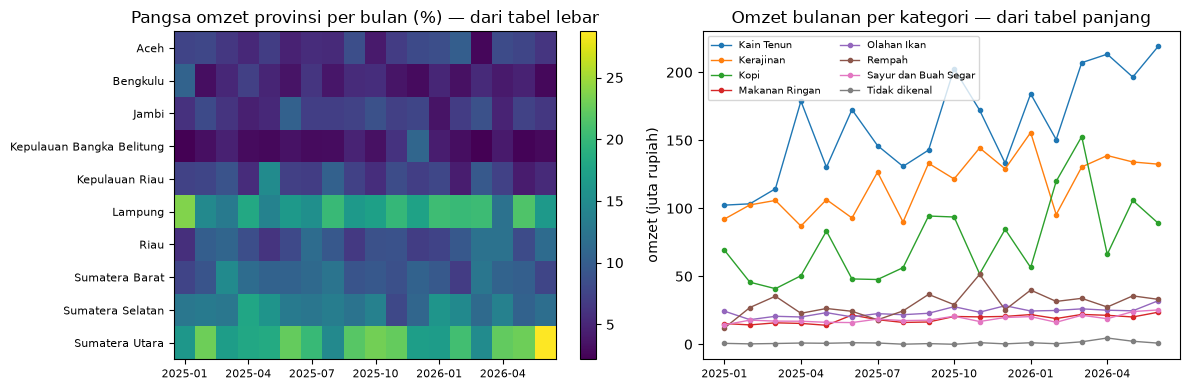

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow((pangsa * 100).to_numpy(), aspect="auto", cmap="viridis")           # bentuk LEBAR
ax[0].set_yticks(range(len(pangsa)), pangsa.index, fontsize=8)
ax[0].set_xticks(range(0, len(pangsa.columns), 3), pangsa.columns[::3], fontsize=8)
ax[0].set_title("Pangsa omzet provinsi per bulan (%) — dari tabel lebar")
fig.colorbar(im, ax=ax[0])
per_kat = ringkasan[ringkasan.metrik.eq("omzet")].groupby(["bulan", "kategori"]).nilai.sum().reset_index()   # bentuk PANJANG
for nama, d in per_kat.groupby("kategori"):
    ax[1].plot(d.bulan, d.nilai / 1e6, marker="o", ms=3, lw=1, label=nama)
ax[1].set_xticks(range(0, len(BULAN), 3), BULAN[::3], fontsize=8)
ax[1].set_ylabel("omzet (juta rupiah)"); ax[1].legend(fontsize=7, ncol=2)
ax[1].set_title("Omzet bulanan per kategori — dari tabel panjang")
fig.tight_layout(); fig.savefig(OUT / "02_pivot_provinsi.png", dpi=110); plt.show()

**Pembahasan C**

- **Pivot direkonsiliasi.** `pv_omzet` 10 provinsi × 18 bulan tanpa sel kosong; jumlah seluruh selnya
  Rp8.024,2 juta = `OMZET`, dan `pv_pesanan` 12.985 = `N_SELESAI`. `margins=True` menambah baris dan
  kolom "Semua". Sumatera Utara memegang 20,3% omzet; pangsa Riau naik 1,95 poin dan Kepulauan Riau
  turun 2,21 poin antara enam bulan pertama dan terakhir. Bulan terbesar Maret 2026 (Rp595,0 juta),
  terkecil Februari 2025 (Rp328,7 juta).
- **`count` pada butir yang salah.** Pivot "pesanan" dari tabel baris dengan `aggfunc="count"`
  menghitung **19.826 baris**, bukan 12.985 pesanan (+52,7%). Pada butir baris, cacah pesanan adalah
  `nunique`.
- **`melt`** mengembalikan 180 baris (10 × 18). Tabel hasil `melt` dan hasil `groupby` langsung memuat
  informasi yang sama tetapi `equals` bernilai `False` sampai nama kolom dan urutan baris disamakan.
  `pivot(melt(pivot))` identik dengan pivot awal. `.pivot()` pada tabel baris gagal (`Index contains
  duplicate entries`): `.pivot()` hanya memindahkan, `pivot_table()` mengagregasi.
- **Sel kosong.** Dari 1.440 kombinasi bulan × provinsi × kategori hanya **1.309** yang punya
  transaksi: 130 sel `"Tidak dikenal"` dan 1 sel biasa (Kain Tenun, Kepulauan Riau, Juli 2025).
  `groupby` tidak membuat baris untuk kombinasi tanpa data; di bentuk lebar sel itu menjadi `NaN`
  (buku ajar Gambar 7.3).
- **Nol atau tidak terdefinisi?** Rata-rata omzet bulanan Kain Tenun ke Kepulauan Riau: Rp12.202.304
  dari 17 bulan yang ada, Rp11.524.399 dari 18 bulan. Untuk `"Tidak dikenal"`, rata-rata omzet bulanan
  per provinsi Rp350.156 (apa adanya) dan **Rp101.017** (kisi lengkap): 3,5 kali lipat. Untuk jumlah
  dan cacah, "tidak ada transaksi" adalah **0**. Untuk rasio (AOV, harga per unit) sel itu **tidak
  terdefinisi** dan harus tetap `NaN`; karena itu ringkasan hanya menyimpan ukuran aditif.
- **Ringkasan kontrak** (`ringkasan_bulanan_m06.parquet`, 5.760 baris = 18 × 10 × 8 × 4 metrik, tanpa
  `NaN`): `omzet` Rp8.024,2 juta dan `baris` 19.826 cocok dengan tabel pesanan. Metrik **`pesanan`
  dijumlah lintas kategori = 18.583**, bukan 12.985: 5.598 kelebihan itu adalah pesanan multi-kategori
  yang terhitung di setiap kategorinya. `pesanan` aditif lintas bulan dan provinsi, **tidak** lintas
  kategori (K-06-007).
- **`crosstab`.** `normalize="columns"` menjawab "dari seluruh baris suatu kanal, berapa porsi tiap
  kategori"; `normalize="index"` menjawab "dari seluruh baris suatu kategori, berapa porsi tiap kanal".
  Komposisi kategori kedua kanal hampir sama (beda terbesar Kerajinan, 0,92 poin). Kain Tenun 7,4%
  baris tetapi 36,1% omzet: cacah baris dan omzet menjawab pertanyaan yang berbeda.
- Kolom bertingkat hasil `unstack` diratakan menjadi `baris_app`, `omzet_web`, dan seterusnya sebelum
  disimpan; CSV tidak menyimpan `MultiIndex`. Grafik 02 memakai bentuk lebar untuk peta panas dan
  bentuk panjang untuk garis per kategori.

## Bagian D — Deret waktu: periode, rata-rata bergulir, dan tren

### D.1 `resample`: harian, mingguan, bulanan

In [67]:
deret = selesai.set_index("waktu_wib").sort_index().total_bayar          # indeks waktu WIB, butir pesanan
ukur = {"sum": "omzet", "count": "pesanan"}
harian = deret.resample("D").agg(["sum", "count"]).rename(columns=ukur)
# minggu Senin-Minggu, diberi label hari Senin-nya
mingguan = deret.resample("W-MON", label="left", closed="left").agg(["sum", "count"]).rename(columns=ukur)
bulanan = deret.resample("MS").agg(["sum", "count"]).rename(columns=ukur)
print(len(harian), "hari |", len(mingguan), "minggu |", len(bulanan), "bulan")
print("rentang:", deret.index.min(), "s.d.", deret.index.max())
mingguan.iloc[[0, 1, -2, -1]]

546 hari | 79 minggu | 18 bulan
rentang: 2025-01-01 00:39:07 s.d. 2026-06-30 23:15:48


,omzet,pesanan
waktu_wib,,
2024-12-30,78534875.0,92
2025-01-06,52081375.0,107
2026-06-22,147462525.0,221
2026-06-29,24691500.0,61


In [68]:
mingguan["hari"] = harian.omzet.resample("W-MON", label="left", closed="left").size()
mingguan["lengkap"] = mingguan.hari.eq(7)
bulanan["hari"] = harian.omzet.resample("MS").size()
bulanan["lengkap"] = bulanan.hari.eq(bulanan.index.days_in_month)
bulanan["omzet_per_hari"] = bulanan.omzet / bulanan.hari
assert np.isclose(mingguan.omzet.sum(), OMZET) and np.isclose(bulanan.omzet.sum(), OMZET) and np.isclose(harian.omzet.sum(), OMZET)
assert np.allclose(bulanan.omzet.to_numpy(), pv_omzet.sum().to_numpy())                # sama dengan jumlah kolom pivot C.1

tak_lengkap = mingguan[~mingguan.lengkap]
B["minggu"], B["minggu_tak_lengkap"] = len(mingguan), {f"{i:%Y-%m-%d}": (int(r.hari), float(r.omzet)) for i, r in tak_lengkap.iterrows()}
B["minggu_median_omzet"] = float(mingguan.omzet[mingguan.lengkap].median())
B["bulan_tak_lengkap"] = int((~bulanan.lengkap).sum())
B["hari"], B["hari_nol"] = len(harian), int(harian.pesanan.eq(0).sum())
B["label_w_bawaan"] = f"{deret.resample('W').sum().index[-1]:%Y-%m-%d}"
per_bulan = bulanan.assign(bulan=bulanan.index.strftime("%Y-%m")).set_index("bulan")
peringkat = pd.DataFrame({"omzet": per_bulan.omzet.rank(ascending=False), "per_hari": per_bulan.omzet_per_hari.rank(ascending=False)})
B["peringkat_berubah"] = peringkat[peringkat.omzet.ne(peringkat.per_hari)].astype(int).to_dict("index")
B["feb26"] = (float(per_bulan.omzet["2026-02"]), float(per_bulan.omzet_per_hari["2026-02"]),
              float(per_bulan.omzet["2026-01"]), float(per_bulan.omzet_per_hari["2026-01"]))
B["mom_feb"] = (100 * (B["feb26"][0] / B["feb26"][2] - 1), 100 * (B["feb26"][1] / B["feb26"][3] - 1))

kecil = selesai.provinsi_tujuan.value_counts().idxmin()
dk_ = selesai[selesai.provinsi_tujuan.eq(kecil)]
B["prov_kecil"] = kecil
B["prov_kecil_groupby"] = int(dk_.groupby(dk_.waktu_wib.dt.date).ngroups)
harian_kecil = dk_.set_index("waktu_wib").total_bayar.resample("D").sum().reindex(harian.index, fill_value=0)
B["prov_kecil_resample"] = len(harian_kecil)

omzet_mingguan = (mingguan.rename_axis("minggu").reset_index()
                  .assign(minggu=lambda d: d.minggu.dt.strftime("%Y-%m-%d"))[["minggu", "omzet", "pesanan", "hari", "lengkap"]])
omzet_mingguan.to_csv(OUT / "omzet_mingguan_m06.csv", index=False)
print(f"{B['minggu']} minggu; tidak lengkap {B['minggu_tak_lengkap']} (median minggu lengkap {juta(B['minggu_median_omzet'])})")
print(f"bulan tidak lengkap: {B['bulan_tak_lengkap']} dari {len(bulanan)}; hari tanpa pesanan: {B['hari_nol']} dari {B['hari']}")
print(f"Feb 2026 vs Jan 2026: omzet {angka(B['mom_feb'][0])}%, omzet per hari {angka(B['mom_feb'][1])}%")
print("peringkat bulan berubah (omzet -> per hari):", B["peringkat_berubah"])
print("label minggu terakhir resample('W') bawaan:", B["label_w_bawaan"])
print(f"{kecil}: groupby(tanggal) {B['prov_kecil_groupby']} baris vs resample('D') {B['prov_kecil_resample']} hari")

79 minggu; tidak lengkap {'2024-12-30': (5, 78534875.0), '2026-06-29': (2, 24691500.0)} (median minggu lengkap 98,3 juta)
bulan tidak lengkap: 0 dari 18; hari tanpa pesanan: 0 dari 546
Feb 2026 vs Jan 2026: omzet -9,2%, omzet per hari 0,5%
peringkat bulan berubah (omzet -> per hari): {'2025-01': {'omzet': 17, 'per_hari': 18}, '2025-02': {'omzet': 18, 'per_hari': 15}, '2025-03': {'omzet': 16, 'per_hari': 17}, '2025-04': {'omzet': 14, 'per_hari': 12}, '2025-05': {'omzet': 11, 'per_hari': 13}, '2025-06': {'omzet': 13, 'per_hari': 11}, '2025-07': {'omzet': 12, 'per_hari': 14}, '2025-08': {'omzet': 15, 'per_hari': 16}, '2025-09': {'omzet': 8, 'per_hari': 9}, '2025-10': {'omzet': 4, 'per_hari': 5}, '2025-11': {'omzet': 7, 'per_hari': 8}, '2026-01': {'omzet': 6, 'per_hari': 7}, '2026-02': {'omzet': 9, 'per_hari': 6}, '2026-04': {'omzet': 5, 'per_hari': 4}}
label minggu terakhir resample('W') bawaan: 2026-07-05
Kepulauan Bangka Belitung: groupby(tanggal) 331 baris vs resample('D') 546 hari


### D.2 Rata-rata bergulir 7 hari

In [69]:
harian["rata_7"] = harian.omzet.rolling(7).mean()                        # 7 hari ke belakang
harian["rata_7_terpusat"] = harian.omzet.rolling(7, center=True).mean()  # 3 hari sebelum, 3 hari sesudah
harian["hari_ke"] = harian.index.dayofweek                               # 0 = Senin
print(harian[["omzet", "rata_7", "rata_7_terpusat"]].isna().sum().to_dict())
harian.groupby("hari_ke").omzet.mean().div(1e6).round(2).to_frame("omzet rata-rata per hari (juta)").T

{'omzet': 0, 'rata_7': 6, 'rata_7_terpusat': 6}


hari_ke,0,1,2,3,4,5,6
omzet rata-rata per hari (juta),14.18,15.27,14.54,15.0,13.0,14.68,16.2


kosong: {'rata_7': 6, 'rata_7_terpusat': 6} | sd harian 6,98 juta -> sd rata-rata 7 hari 3,32 juta
hari tertinggi Minggu 16,20 juta, terendah Jumat 13,00 juta
Kepulauan Bangka Belitung: '7 baris' mencakup median 11 hari kalender, maksimum 21; rata-rata bergulir Rp947.337 (bolong) vs Rp572.660 (per hari kalender)


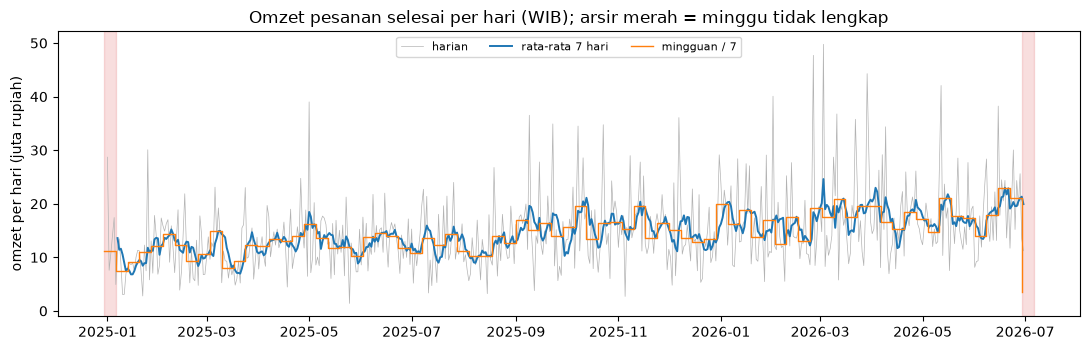

In [70]:
B["rolling_na"] = harian[["rata_7", "rata_7_terpusat"]].isna().sum().to_dict()
per_hari_ke = harian.groupby("hari_ke").omzet.mean()
NAMA_HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
B["hari_tertinggi"] = (NAMA_HARI[int(per_hari_ke.idxmax())], float(per_hari_ke.max()))
B["hari_terendah"] = (NAMA_HARI[int(per_hari_ke.idxmin())], float(per_hari_ke.min()))
B["sd_harian"], B["sd_rata7"] = float(harian.omzet.std()), float(harian.rata_7.std())
bolong = dk_.groupby(dk_.waktu_wib.dt.normalize()).total_bayar.sum()
rentang7 = pd.Series((bolong.index[6:] - bolong.index[:-6]).days + 1)            # hari kalender yang dicakup 7 baris
B["rentang7_median"], B["rentang7_maks"] = float(rentang7.median()), int(rentang7.max())
r_bolong = bolong.rolling(7).mean()
r_benar = harian_kecil.rolling(7).mean()
B["rolling_bolong_rata"], B["rolling_benar_rata"] = float(r_bolong.mean()), float(r_benar.mean())
print(f"kosong: {B['rolling_na']} | sd harian {juta(B['sd_harian'], 2)} -> sd rata-rata 7 hari {juta(B['sd_rata7'], 2)}")
print(f"hari tertinggi {B['hari_tertinggi'][0]} {juta(B['hari_tertinggi'][1], 2)}, terendah {B['hari_terendah'][0]} {juta(B['hari_terendah'][1], 2)}")
print(f"{kecil}: '7 baris' mencakup median {B['rentang7_median']:.0f} hari kalender, maksimum {B['rentang7_maks']}; "
      f"rata-rata bergulir {rp(B['rolling_bolong_rata'])} (bolong) vs {rp(B['rolling_benar_rata'])} (per hari kalender)")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(harian.index, harian.omzet / 1e6, lw=.5, color="0.7", label="harian")
ax.plot(harian.index, harian.rata_7 / 1e6, lw=1.4, color="C0", label="rata-rata 7 hari")
ax.step(mingguan.index, mingguan.omzet / 7e6, where="post", lw=1, color="C1", label="mingguan / 7")
for i in tak_lengkap.index:
    ax.axvspan(i, i + pd.Timedelta(days=7), color="C3", alpha=.15)
ax.set_ylabel("omzet per hari (juta rupiah)"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Omzet pesanan selesai per hari (WIB); arsir merah = minggu tidak lengkap")
fig.tight_layout(); fig.savefig(OUT / "03_deret_harian.png", dpi=110); plt.show()

### D.3 Tren linear dan batas ekstrapolasi

In [71]:
def tren(y: pd.Series) -> dict:
    """Regresi linear y terhadap indeks waktu 0..n-1 (buku ajar Bab 7.5.4)."""
    x = np.arange(len(y)).reshape(-1, 1)
    model = LinearRegression().fit(x, y.to_numpy())
    return {"n": len(y), "kemiringan": float(model.coef_[0]), "intersep": float(model.intercept_),
            "r2": float(model.score(x, y.to_numpy()))}


y_semua = mingguan.omzet / 1e6            # juta rupiah per minggu
tren(y_semua)

{'n': 79, 'kemiringan': 0.6563791753894839, 'intersep': 75.9739969699367, 'r2': 0.37087328261213826}

       lingkup  n_minggu  kemiringan_juta_per_minggu  intersep_juta     r2
  semua_minggu        79                      0.6564        75.9740 0.3709
minggu_lengkap        77                      0.7641        73.8355 0.5397
minggu tidak lengkap mengubah kemiringan -14,1%
uji mundur (52 minggu 2025 -> 25 minggu 2026): tren MAE 13,97 juta (12,0%), bias 0,71; naif MAE 19,16 juta (15,0%), bias -13,74; kemiringan 2025 0,773
ekstrapolasi +52 minggu: 171,6 juta/minggu (garis kini 131,9; sd sisaan 15,9); setara tumbuh 30,1% setahun


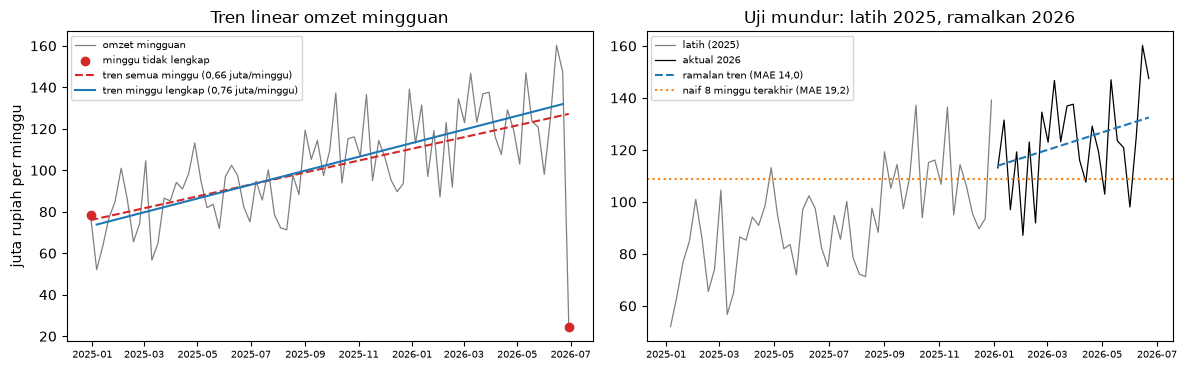

In [72]:
y_lengkap = y_semua[mingguan.lengkap]
t_semua, t_lengkap = tren(y_semua), tren(y_lengkap)
tren_tabel = pd.DataFrame([
    {"lingkup": "semua_minggu", "n_minggu": t_semua["n"], "kemiringan_juta_per_minggu": t_semua["kemiringan"],
     "intersep_juta": t_semua["intersep"], "r2": t_semua["r2"]},
    {"lingkup": "minggu_lengkap", "n_minggu": t_lengkap["n"], "kemiringan_juta_per_minggu": t_lengkap["kemiringan"],
     "intersep_juta": t_lengkap["intersep"], "r2": t_lengkap["r2"]}])
tren_tabel.to_csv(OUT / "tren_m06.csv", index=False)
B["tren_semua"], B["tren_lengkap"] = t_semua, t_lengkap
B["tren_beda_persen"] = 100 * (t_semua["kemiringan"] / t_lengkap["kemiringan"] - 1)

# uji mundur: latih 2025, ramalkan 2026
latih, uji = y_lengkap[y_lengkap.index.year == 2025], y_lengkap[y_lengkap.index.year == 2026]
t_latih = tren(latih)
x_uji = np.arange(len(latih), len(latih) + len(uji))
ramal = pd.Series(t_latih["intersep"] + t_latih["kemiringan"] * x_uji, index=uji.index)
naif = float(latih.iloc[-8:].mean())
B["uji"] = {"n_latih": len(latih), "n_uji": len(uji), "kemiringan_latih": t_latih["kemiringan"],
            "mae": float((uji - ramal).abs().mean()), "mape": 100 * float(((uji - ramal).abs() / uji).mean()),
            "bias": float((ramal - uji).mean()),
            "mae_naif": float((uji - naif).abs().mean()), "mape_naif": 100 * float(((uji - naif).abs() / uji).mean()),
            "bias_naif": float((naif - uji).mean())}

# ekstrapolasi 52 minggu ke depan dari tren minggu lengkap
x_l = np.arange(len(y_lengkap))
garis_l = t_lengkap["intersep"] + t_lengkap["kemiringan"] * x_l
sisa = y_lengkap.to_numpy() - garis_l
B["sd_sisa"] = float(sisa.std(ddof=2))
B["akhir_garis"] = float(garis_l[-1])
B["ramal_52"] = float(t_lengkap["intersep"] + t_lengkap["kemiringan"] * (len(y_lengkap) - 1 + 52))
B["tumbuh_tahunan_persen"] = 100 * (52 * t_lengkap["kemiringan"]) / float(garis_l[-1])
B["rata_minggu"] = float(y_lengkap.mean())
print(tren_tabel.round(4).to_string(index=False))
print(f"minggu tidak lengkap mengubah kemiringan {angka(B['tren_beda_persen'])}%")
print(f"uji mundur ({B['uji']['n_latih']} minggu 2025 -> {B['uji']['n_uji']} minggu 2026): tren MAE {angka(B['uji']['mae'], 2)} juta "
      f"({angka(B['uji']['mape'])}%), bias {angka(B['uji']['bias'], 2)}; naif MAE {angka(B['uji']['mae_naif'], 2)} juta "
      f"({angka(B['uji']['mape_naif'])}%), bias {angka(B['uji']['bias_naif'], 2)}; kemiringan 2025 {angka(B['uji']['kemiringan_latih'], 3)}")
print(f"ekstrapolasi +52 minggu: {angka(B['ramal_52'])} juta/minggu (garis kini {angka(B['akhir_garis'])}; sd sisaan {angka(B['sd_sisa'])}); "
      f"setara tumbuh {angka(B['tumbuh_tahunan_persen'])}% setahun")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(y_semua.index, y_semua, lw=.9, color="0.5", label="omzet mingguan")
ax[0].scatter(tak_lengkap.index, tak_lengkap.omzet / 1e6, color="C3", zorder=3, label="minggu tidak lengkap")
ax[0].plot(y_semua.index, t_semua["intersep"] + t_semua["kemiringan"] * np.arange(len(y_semua)), "C3--",
           label=f"tren semua minggu ({angka(t_semua['kemiringan'], 2)} juta/minggu)")
ax[0].plot(y_lengkap.index, garis_l, "C0", label=f"tren minggu lengkap ({angka(t_lengkap['kemiringan'], 2)} juta/minggu)")
ax[0].set_ylabel("juta rupiah per minggu"); ax[0].legend(fontsize=7); ax[0].set_title("Tren linear omzet mingguan")
ax[1].plot(latih.index, latih, lw=.9, color="0.5", label="latih (2025)")
ax[1].plot(uji.index, uji, lw=.9, color="k", label="aktual 2026")
ax[1].plot(uji.index, ramal, "C0--", label=f"ramalan tren (MAE {angka(B['uji']['mae'], 1)})")
ax[1].axhline(naif, color="C1", ls=":", label=f"naif 8 minggu terakhir (MAE {angka(B['uji']['mae_naif'], 1)})")
ax[1].legend(fontsize=7); ax[1].set_title("Uji mundur: latih 2025, ramalkan 2026")
for a_ in ax:
    a_.tick_params(axis="x", labelsize=7)
fig.tight_layout(); fig.savefig(OUT / "04_tren_mingguan.png", dpi=110); plt.show()

### D.4 Log keputusan

In [73]:
KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama_log = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
                else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama_log[~lama_log.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    if path.parent != MODUL:
        shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log

In [74]:
log = catat_keputusan([
    {"id": "K-06-001", "modul": 6, "sumber_kolom": "transaksi_m04.id_pesanan;transaksi_m04.baris_ke;transaksi_m04.waktu_wib",
     "temuan": "butir transaksi adalah baris pesanan; waktu_wib tidak sama di semua baris pada sebagian pesanan",
     "bukti": (f"{B['n_baris']} baris = {B['n_pesanan']} pesanan (1-{max(B['baris_per_pesanan'])} baris); waktu kosong {B['waktu_nat_baris']} baris: "
               f"{B['pesanan_nat_semua']} pesanan kosong seluruhnya, {B['pesanan_nat_sebagian']} sebagian; "
               f"drop_duplicates kehilangan waktu {B['pintas_kehilangan_waktu']} pesanan"),
     "tindakan": "pesanan_m06 = groupby id_pesanan dengan agregasi bernama; waktu_wib pesanan = min() baris; pesanan tanpa waktu dipertahankan dengan bulan kosong",
     "alasan": "drop_duplicates mengambil baris pertama apa adanya dan membuang ongkir serta total baris lain; menghapus pesanan tanpa waktu menghilangkan baris tanpa catatan",
     "baris_terdampak": B["pesanan_nat_sebagian"], "id_anomali": "A-11"},
    {"id": "K-06-002", "modul": 6, "sumber_kolom": "transaksi_m04.ongkir;transaksi_m04.total_bayar",
     "temuan": "ongkir berbutir baris pesanan dan sudah termuat dalam total_bayar",
     "bukti": (f"identitas cocok pada {B['identitas_cocok']} baris; ongkir sama di semua baris hanya pada {B['multi_ongkir_sama']} dari {B['multi']} pesanan multi-baris; "
               f"total + ongkir {angka(B['kandidat'].selisih_persen.iloc[1], 2)}%, ongkir pertama {angka(B['kandidat'].selisih_persen.iloc[2], 2)}%, "
               f"baris pertama saja {angka(B['kandidat'].selisih_persen.iloc[4], 2)}%"),
     "tindakan": "ongkir pesanan = sum(ongkir); total_bayar pesanan = sum(total_bayar); nilai_barang = total_bayar - ongkir; direkonsiliasi dengan assert",
     "alasan": "menambahkan ongkir ke total_bayar menghitungnya dua kali; first() atau max() memperlakukan ongkir sebagai atribut pesanan padahal bukan",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-06-003", "modul": 6, "sumber_kolom": "pesanan_m06.status;pesanan_m06.waktu_wib",
     "temuan": "pesanan dibatalkan, dikembalikan, dan diproses masih membawa total_bayar",
     "bukti": (f"semua status {juta(B['total_semua_status'])} vs selesai berwaktu sah {juta(B['omzet'])} ({angka(B['inflasi_status_persen'])}% lebih besar); "
               f"{B['selesai_tanpa_waktu']} pesanan selesai tanpa waktu ({juta(B['selesai_tanpa_waktu_rp'], 2)})"),
     "tindakan": "omzet = total_bayar pesanan berstatus selesai dengan waktu pesanan sah; definisi ditulis sekali (selesai, OMZET) dan dipakai semua tabel",
     "alasan": "pesanan dibatalkan dan dikembalikan bukan pendapatan; diproses belum pasti; pesanan tanpa waktu tidak dapat ditempatkan pada bulan mana pun",
     "baris_terdampak": B["n_pesanan"] - B["n_selesai"], "id_anomali": "A-11"},
    {"id": "K-06-004", "modul": 6, "sumber_kolom": "pesanan_m06.total_bayar",
     "temuan": "rata-rata per baris bukan rata-rata nilai pesanan; rata-rata atas rata-rata bukan rata-rata keseluruhan",
     "bukti": (f"per baris {rp(B['rata_baris_selesai'])}, per pesanan {rp(B['aov'])}, median {rp(B['median_pesanan'])}; rata-rata 10 AOV provinsi "
               f"{rp(B['rata_dari_rata'])}; rata-rata 7 harga kategori {rp(B['harga_rata_dari_rata'])} vs seluruh baris {rp(B['harga_rata_semua'])}"),
     "tindakan": "AOV = jumlah omzet / banyak pesanan pada butir pesanan; rasio antarkelompok dihitung dari jumlah pembilang dan penyebut, atau ditimbang",
     "alasan": "mean() kolom total_bayar pada tabel baris memakai baris sebagai penyebut; rata-rata tak tertimbang memberi bobot sama pada kelompok kecil dan besar",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-06-005", "modul": 6, "sumber_kolom": "transaksi_m04.diskon_persen;transaksi_m04.pembelian_grosir",
     "temuan": "rata-rata diskon per baris berbeda dari diskon efektif karena pembelian grosir bernilai besar",
     "bukti": (f"{B['diskon_beda_kategori']}: rata-rata baris {angka(B['diskon_beda'][0], 2)}% vs efektif {angka(B['diskon_beda'][1], 2)}%; "
               f"grosir {B['grosir_baris']} baris berdiskon rata-rata {angka(B['grosir_diskon'], 2)}%; "
               f"pesanan memuat grosir {angka(100 * B['grosir_omzet'] / B['omzet'])}% omzet"),
     "tindakan": "diskon_efektif = jumlah(diskon x nilai kotor) / jumlah(nilai kotor); harga_per_unit = nilai kotor / unit; pesanan grosir tetap dihitung dan diberi bendera ada_grosir",
     "alasan": "pembelian grosir sah (Modul 3) sehingga tidak dibuang; rata-rata per baris tidak menjawab berapa persen nilai yang didiskon",
     "baris_terdampak": 0, "id_anomali": "A-17"},
    {"id": "K-06-006", "modul": 6, "sumber_kolom": "produk_m04.kategori;transaksi_m04.produk_dikenal",
     "temuan": "baris berkode produk di luar katalog tidak punya kategori dan dibuang diam-diam oleh groupby",
     "bukti": (f"{B['kategori_kosong_semua']} baris tanpa kategori ({B['kategori_kosong_baris']} pada pesanan selesai, {juta(B['kategori_kosong_rp'], 2)}); "
               f"tabel per kategori hanya memuat {B['dk_baris_awal']} baris"),
     "tindakan": f"kategori kosong diberi label '{TAK_DIKENAL}'; setiap tabel per kategori direkonsiliasi dengan jumlah baris dan omzet",
     "alasan": "groupby dan pivot_table membuang kunci kosong secara bawaan sehingga total tidak cocok; barisnya nyata dan ikut omzet",
     "baris_terdampak": B["kategori_kosong_semua"], "id_anomali": "A-16"},
    {"id": "K-06-007", "modul": 6, "sumber_kolom": "ringkasan_bulanan_m06.nilai",
     "temuan": "kombinasi bulan x provinsi x kategori tanpa transaksi tidak muncul sebagai baris",
     "bukti": (f"{B['sel_terisi']} dari {B['sel_semua']} kombinasi terisi; rata-rata omzet bulanan '{TAK_DIKENAL}' per provinsi "
               f"{rp(B['tak_dikenal_rata_apa_adanya'])} (apa adanya) vs {rp(B['tak_dikenal_rata_lengkap'])} (lengkap); "
               f"pesanan dijumlah lintas kategori {B['pesanan_dijumlah_kategori']} vs {B['n_selesai']}"),
     "tindakan": "tabel dilengkapi dengan MultiIndex.from_product dan reindex(fill_value=0) untuk omzet, pesanan, baris, unit; metrik pesanan dicatat tidak aditif lintas kategori",
     "alasan": "tidak ada transaksi berarti nol untuk jumlah dan cacah; rasio seperti AOV pada sel kosong tidak terdefinisi dan tidak disimpan",
     "baris_terdampak": (B["sel_semua"] - B["sel_terisi"]) * 4, "id_anomali": "-"},
    {"id": "K-06-008", "modul": 6, "sumber_kolom": "pesanan_m06.waktu_wib",
     "temuan": "minggu pertama dan terakhir tidak lengkap dan menarik garis tren",
     "bukti": ("minggu tidak lengkap " + ", ".join(f"{k_} ({v_[0]} hari, {juta(v_[1])})" for k_, v_ in B["minggu_tak_lengkap"].items())
               + f"; kemiringan {angka(B['tren_semua']['kemiringan'], 3)} (semua) vs "
               f"{angka(B['tren_lengkap']['kemiringan'], 3)} juta/minggu (lengkap), beda {angka(B['tren_beda_persen'])}%; "
               f"uji mundur MAPE tren {angka(B['uji']['mape'])}% vs naif {angka(B['uji']['mape_naif'])}%"),
     "tindakan": "tren dihitung pada minggu lengkap (Senin-Minggu, label hari Senin, WIB); minggu tidak lengkap tetap ada di omzet_mingguan_m06.csv dengan lengkap=False",
     "alasan": "periode yang terpotong bukan penurunan penjualan; membuangnya dari tabel menghilangkan omzet, sehingga hanya dikeluarkan dari regresi",
     "baris_terdampak": len(B["minggu_tak_lengkap"]), "id_anomali": "-"},
])
log[log.id.str.startswith("K-06")][["id", "sumber_kolom", "baris_terdampak", "id_anomali"]]

,id,sumber_kolom,baris_terdampak,id_anomali
0,K-06-001,transaksi_m04.id_pesanan;transaksi_m04.baris_k...,10,A-11
1,K-06-002,transaksi_m04.ongkir;transaksi_m04.total_bayar,0,-
2,K-06-003,pesanan_m06.status;pesanan_m06.waktu_wib,2759,A-11
3,K-06-004,pesanan_m06.total_bayar,0,-
4,K-06-005,transaksi_m04.diskon_persen;transaksi_m04.pemb...,0,A-17
5,K-06-006,produk_m04.kategori;transaksi_m04.produk_dikenal,76,A-16
6,K-06-007,ringkasan_bulanan_m06.nilai,524,-
7,K-06-008,pesanan_m06.waktu_wib,2,-
17,K-06-009,pesanan_m06.id_entitas;pesanan_m06.bulan,213,-
18,K-06-010,dasbor_*_m06.csv;rekonsiliasi_m06.csv,10,-


**Pembahasan D**

- **Periode.** 546 hari (1 Januari 2025 – 30 Juni 2026), tidak ada hari tanpa pesanan; 18 bulan,
  semuanya lengkap; **79 minggu, 2 tidak lengkap**: minggu 30 Desember 2024 (5 hari, Rp78,5 juta) dan
  minggu 29 Juni 2026 (**2 hari, Rp24,7 juta**; median minggu lengkap Rp98,3 juta). Jumlah harian,
  mingguan, dan bulanan sama-sama Rp8.024,2 juta, dan omzet bulanan sama dengan jumlah kolom pivot C.1.
- `resample("W")` bawaan memberi label **2026-07-05** pada minggu terakhir: tanggal yang belum terjadi.
  Label hari Senin (`label="left", closed="left"`) menunjuk awal periode yang benar-benar teramati.
- **Bulan tidak sama panjang.** Februari 2026 terhadap Januari 2026: omzet −9,2%, omzet per hari
  **+0,5%**. Empat belas dari 18 bulan berubah peringkat bila diukur per hari (Februari 2025 dari
  peringkat 18 ke 15, Februari 2026 dari 9 ke 6).
- **Hari yang hilang.** Untuk Kepulauan Bangka Belitung, `groupby(tanggal)` hanya memberi 331 baris;
  `resample("D")` memberi 546 hari. `rolling(7)` pada tabel 331 baris itu mencakup median 11 hari
  kalender (maksimum 21), dan rata-rata bergulirnya Rp947.337 padahal per hari kalender Rp572.660
  (65% terlalu tinggi), karena hari tanpa pesanan tidak pernah dihitung sebagai nol.
- **Rata-rata 7 hari.** Enam nilai pertama kosong (jendela belum penuh; versi terpusat kosong 3 di awal
  dan 3 di akhir). `min_periods=1` mengisinya dengan rata-rata 1–6 hari yang tidak sebanding. Jendela
  7 dipilih karena pola mingguan: Minggu Rp16,20 juta, Jumat Rp13,00 juta. Simpangan baku harian
  Rp6,98 juta turun menjadi Rp3,32 juta.
- **Tren.** Semua minggu: 0,656 juta/minggu (R² 0,371). Minggu lengkap: **0,764 juta/minggu** (R² 0,540).
  Dua titik di ujung deret menurunkan kemiringan **14,1%**; titik di ujung paling berpengaruh pada
  regresi. Minggu itu tetap ada di `omzet_mingguan_m06.csv` (`lengkap=False`); yang dikeluarkan hanya
  dari regresi.
- **Uji mundur.** Tren 52 minggu 2025 (0,773 juta/minggu) meramal 25 minggu 2026 dengan galat absolut
  rata-rata Rp13,97 juta (12,0%) dan bias +0,71; ramalan naif "rata-rata 8 minggu terakhir" Rp19,16
  juta (15,0%), bias −13,74. Di sini tren menang, tetapi galatnya masih seperdelapan omzet mingguan.
- **Ekstrapolasi.** Garis kini Rp131,9 juta/minggu; 52 minggu ke depan Rp171,6 juta/minggu (+30,1%).
  Simpangan baku sisaan Rp15,9 juta; R² 0,54 berarti hampir separuh variasi tidak dijelaskan garis.
  Data hanya 18 bulan sehingga musim tahunan tidak dapat dipisahkan dari tren, dan garis lurus tidak
  tahu apa pun tentang kapasitas, promosi, atau pesaing. Angka itu skenario "bila semuanya terus sama",
  bukan ramalan.

## Latihan 6.1 — Kohort pelanggan dan retensi

**Dinilai.** Kerjakan di laboratorium; jawabannya ditulis pada **`dw-module-06/latihan-kohort.md`** dan
diunggah ke tugas *Latihan Mandiri di Lab — Modul 06*.

Kohort = pelanggan yang **pesanan selesai pertamanya** jatuh pada bulan yang sama. Retensi bulan
ke-*n* = porsi anggota kohort yang memesan lagi (pesanan selesai) pada bulan ke-*n* sesudahnya.

1. Dari `selesai`, bentuk tabel kohort memakai `id_entitas`: `kohort` (bulan pesanan pertama),
   `bulan_ke` (0, 1, 2, …), `pelanggan` (banyak entitas berbeda yang memesan), `ukuran_kohort`, dan
   `retensi = pelanggan / ukuran_kohort`. Gunakan `transform` untuk bulan pertama. Pembeli tamu
   diapakan, dan berapa pesanannya?
2. Ubah ke bentuk lebar (kohort × bulan ke-*n*). Sel di kanan bawah segitiga kosong: apakah itu 0?
   Simpan bentuk **panjang** ke `keluaran/kohort_m06.csv` tanpa baris untuk sel yang belum teramati,
   dan peta panasnya ke `keluaran/05_kohort.png`.
3. Hitung retensi bulan ke-1 dengan dua cara: rata-rata sederhana antarkohort dan jumlah pelanggan
   kembali dibagi jumlah ukuran kohort. Mengapa berbeda, dan mana yang Anda laporkan? Hitung juga
   rata-rata retensi bulan ke-6 antarkohort dengan sel kosong dibiarkan dan dengan sel kosong diisi 0.
4. Ulangi butir 1 dengan `id_pelanggan`. Berapa ukuran kohort total dan retensi bulan ke-1 sekarang,
   dan mengapa?

In [75]:
def idx_bulan(s):
    """'2025-03' -> 2025*12+3, supaya selisih bulan mudah dihitung."""
    s = pd.Series(s).astype(str)
    return s.str[:4].astype(int) * 12 + s.str[5:7].astype(int)
 
 
def kohort_panjang(df, kunci):
    """Tabel kohort bentuk panjang. Kunci kosong (pembeli tamu) dibuang dan dicatat terpisah."""
    d = df[df[kunci].notna()].copy()
    d["kohort"] = d.groupby(kunci).bulan.transform("min")          # bulan pesanan selesai pertama
    d["bulan_ke"] = idx_bulan(d.bulan).to_numpy() - idx_bulan(d.kohort).to_numpy()
    k = d.groupby(["kohort", "bulan_ke"]).agg(pelanggan=(kunci, "nunique")).reset_index()
    ukuran = k[k.bulan_ke.eq(0)].set_index("kohort").pelanggan
    k["ukuran_kohort"] = k.kohort.map(ukuran)
    k["retensi"] = k.pelanggan / k.ukuran_kohort
    return k, ukuran
 
 
AKHIR = int(idx_bulan([BULAN[-1]]).iloc[0])
 
 
def lebar_kohort(k, ukuran):
    """Bentuk lebar. Sel yang SUDAH teramati tapi tak ada yang kembali = 0;
    sel di luar rentang data (segitiga kanan bawah) = NaN (belum teramati)."""
    P = k.pivot(index="kohort", columns="bulan_ke", values="pelanggan").reindex(columns=range(len(BULAN)))
    for ko in P.index:
        maks = AKHIR - int(idx_bulan([ko]).iloc[0])
        kolom = [c for c in P.columns if c <= maks]
        P.loc[ko, kolom] = P.loc[ko, kolom].fillna(0)
    R = P.div(ukuran.reindex(P.index), axis=0)
    return P, R
 
 
def ringkas_retensi(P, R, ukuran, n):
    ada = P[n].notna()
    uk = ukuran.reindex(P.index)
    return {"n_kohort": int(ada.sum()),
            "sederhana": float(R.loc[ada, n].mean()),
            "tertimbang": float(P.loc[ada, n].sum() / uk[ada].sum())}

pembeli tamu dikeluarkan: 213 pesanan (147,2 juta)
ukuran kohort total: 4491 | kohort: 18
sel belum teramati (NaN): 153 dari 324
bulan ke-1: sederhana 14,00% vs tertimbang 13,58% (17 kohort teramati)
bulan ke-6: NaN dibiarkan 13,64% (12 kohort) vs diisi 0 9,10% (18 kohort)
ukuran kohort total: id_entitas 4491 vs id_pelanggan 5099
retensi bulan ke-1 (tertimbang): id_entitas 13,58% vs id_pelanggan 12,28%


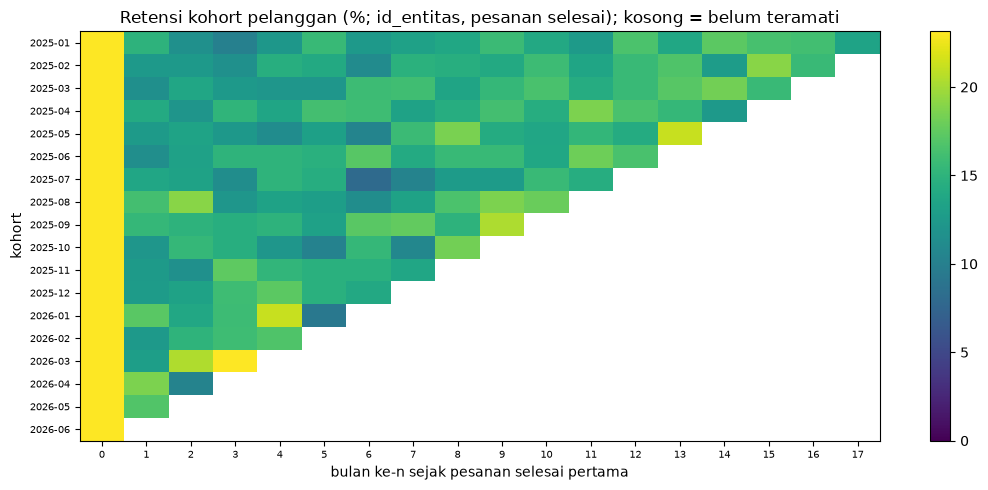

In [76]:
# TODO 1: tabel kohort panjang dari `selesai` (id_entitas; pembeli tamu?)
tamu = selesai[selesai.id_entitas.isna()]
B["selesai_tamu"], B["selesai_tamu_rp"] = len(tamu), float(tamu.total_bayar.sum())
k_e, ukuran_e = kohort_panjang(selesai, "id_entitas")
assert ukuran_e.sum() == selesai.id_entitas.nunique()
print(f"pembeli tamu dikeluarkan: {B['selesai_tamu']} pesanan ({juta(B['selesai_tamu_rp'])})")
print("ukuran kohort total:", int(ukuran_e.sum()), "| kohort:", len(ukuran_e))
k_e.head()

# TODO 2: bentuk lebar, sel belum teramati (NaN, bukan 0), simpan OUT / "kohort_m06.csv" dan "05_kohort.png"
P_e, R_e = lebar_kohort(k_e, ukuran_e)
print("sel belum teramati (NaN):", int(P_e.isna().sum().sum()), "dari", P_e.size)
 
kohort_csv = (P_e.rename_axis(columns=None).reset_index()
                 .melt(id_vars="kohort", var_name="bulan_ke", value_name="pelanggan")
                 .dropna(subset=["pelanggan"]))                    # tanpa baris untuk sel belum teramati
kohort_csv["pelanggan"] = kohort_csv.pelanggan.astype(int)
kohort_csv["ukuran_kohort"] = kohort_csv.kohort.map(ukuran_e).astype(int)
kohort_csv["retensi"] = kohort_csv.pelanggan / kohort_csv.ukuran_kohort
kohort_csv = kohort_csv.sort_values(["kohort", "bulan_ke"]).reset_index(drop=True)
kohort_csv.to_csv(OUT / "kohort_m06.csv", index=False)
 
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow((R_e * 100).to_numpy(), aspect="auto", cmap="viridis", vmin=0,
               vmax=float(np.nanmax(R_e.iloc[:, 1:].to_numpy()) * 100))   # NaN tampil kosong
ax.set_yticks(range(len(R_e)), R_e.index, fontsize=7)
ax.set_xticks(range(R_e.shape[1]), R_e.columns, fontsize=7)
ax.set_xlabel("bulan ke-n sejak pesanan selesai pertama"); ax.set_ylabel("kohort")
ax.set_title("Retensi kohort pelanggan (%; id_entitas, pesanan selesai); kosong = belum teramati")
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(OUT / "05_kohort.png", dpi=110); plt.show()

# TODO 3: retensi bulan ke-1: rata-rata antarkohort vs tertimbang; bulan ke-6: sel kosong dibiarkan vs diisi 0
r1 = ringkas_retensi(P_e, R_e, ukuran_e, 1)
B["ret1_sederhana"], B["ret1_tertimbang"], B["ret1_n_kohort"] = r1["sederhana"], r1["tertimbang"], r1["n_kohort"]
B["ret6_dibiarkan"] = float(R_e[6].mean())              # NaN diabaikan
B["ret6_isi0"] = float(R_e[6].fillna(0).mean())         # NaN dipaksa 0 (menyesatkan)
B["ret6_n_kohort"] = int(R_e[6].notna().sum())
print(f"bulan ke-1: sederhana {angka(100*r1['sederhana'], 2)}% vs tertimbang {angka(100*r1['tertimbang'], 2)}% "
      f"({r1['n_kohort']} kohort teramati)")
print(f"bulan ke-6: NaN dibiarkan {angka(100*B['ret6_dibiarkan'], 2)}% ({B['ret6_n_kohort']} kohort) "
      f"vs diisi 0 {angka(100*B['ret6_isi0'], 2)}% ({len(R_e)} kohort)")
 
# TODO 4: ulangi dengan id_pelanggan; bandingkan
k_p, ukuran_p = kohort_panjang(selesai, "id_pelanggan")
P_p, R_p = lebar_kohort(k_p, ukuran_p)
r1p = ringkas_retensi(P_p, R_p, ukuran_p, 1)
B["ukuran_total_entitas"], B["ukuran_total_id"] = int(ukuran_e.sum()), int(ukuran_p.sum())
B["ret1_tertimbang_id"] = r1p["tertimbang"]
print(f"ukuran kohort total: id_entitas {B['ukuran_total_entitas']} vs id_pelanggan {B['ukuran_total_id']}")
print(f"retensi bulan ke-1 (tertimbang): id_entitas {angka(100*r1['tertimbang'], 2)}% vs id_pelanggan {angka(100*r1p['tertimbang'], 2)}%")

**Jawaban Latihan 6.1** — tulis di `latihan-kohort.md`: perlakuan pembeli tamu, tabel retensi
(beberapa kohort dan beberapa bulan), arti sel kosong, dua angka retensi bulan ke-1 beserta alasannya,
dan perbandingan `id_entitas` dengan `id_pelanggan`.

## Latihan 6.2 — Bolak-balik `melt` dan `pivot`

**Dinilai.** Jawabannya ditulis pada **`dw-module-06/latihan-bolak-balik.md`**.

Transformasi struktural "mengubah bentuk tanpa mengubah makna" (buku ajar Bab 7.2). Buktikan dengan
`DataFrame.equals`, yang menuntut nilai, tipe, indeks, dan urutan yang sama.

1. **Lebar → panjang → lebar.** Dari `pv_omzet` (C.1): `melt`, lalu `pivot`. Apakah `equals` langsung
   `True`? Catat setiap hal yang harus disamakan. Apa yang terjadi bila `melt` dipanggil tanpa
   `reset_index()`?
2. **Panjang → lebar → panjang, tabel berlubang.** Ambil omzet per (provinsi, kategori) **satu bulan**
   dari `sel` (C.3) — bulan yang punya kombinasi kosong. `unstack`, lalu `stack`/`melt` kembali.
   Berapa baris sebelum dan sesudah? Apa yang harus dilakukan agar `equals` kembali `True`, dan
   informasi apa yang berubah bila sel kosong diisi 0?
3. **Tipe.** Lakukan bolak-balik pada metrik `pesanan` (bilangan bulat) dari tabel berlubang yang
   sama. Tipe apa yang kembali, dan mengapa?
4. Simpan `keluaran/bolak_balik_m06.csv`: satu baris per percobaan (`percobaan`, `baris_awal`,
   `baris_akhir`, `equals_langsung`, `equals_setelah_dirapikan`, `yang_disamakan`).

In [77]:
# TODO 1: pv_omzet -> melt -> pivot -> equals?
lebar0 = pv_omzet.copy()
panjang1 = lebar0.reset_index().melt(id_vars="provinsi_tujuan", var_name="bulan", value_name="omzet")
kembali1 = panjang1.pivot(index="provinsi_tujuan", columns="bulan", values="omzet")
eq1_langsung = bool(kembali1.equals(lebar0))
eq1_rapi = bool(kembali1.reindex(index=lebar0.index, columns=lebar0.columns).equals(lebar0))
tanpa_reset = lebar0.melt()                                  # lupa reset_index()
print("1. equals langsung:", eq1_langsung, "| setelah urutan disamakan:", eq1_rapi)
print("   melt tanpa reset_index:", tanpa_reset.shape, list(tanpa_reset.columns), "-> kolom provinsi hilang")

# TODO 2: tabel berlubang (satu bulan, provinsi x kategori): unstack -> stack/melt -> equals?
per_bulan_n = sel.groupby(level="bulan").size()
bulan_b = per_bulan_n[per_bulan_n < len(PROVINSI) * len(KATEGORI)].index[0]
omz = sel.xs(bulan_b, level="bulan").omzet
asal2 = omz.reset_index().sort_values(["provinsi", "kategori"]).reset_index(drop=True)
lebar2 = omz.unstack("kategori")
panjang2 = lebar2.reset_index().melt(id_vars="provinsi", var_name="kategori", value_name="omzet")
rapi2 = (panjang2.dropna(subset=["omzet"]).sort_values(["provinsi", "kategori"]).reset_index(drop=True))
eq2_langsung = bool(panjang2.equals(asal2))
eq2_rapi = bool(rapi2.equals(asal2))
isi0 = lebar2.fillna(0).reset_index().melt(id_vars="provinsi", var_name="kategori", value_name="omzet")
print(f"2. bulan {bulan_b}: baris awal {len(asal2)} -> setelah melt {len(panjang2)} (NaN {int(panjang2.omzet.isna().sum())}) "
      f"-> setelah dropna {len(rapi2)}")
print("   equals langsung:", eq2_langsung, "| setelah dropna+urut:", eq2_rapi, "| bila diisi 0:", len(isi0), "baris")

# TODO 3: metrik pesanan (int) lewat tabel berlubang: tipe apa yang kembali?
pes = sel.xs(bulan_b, level="bulan").pesanan
asal3 = pes.reset_index().sort_values(["provinsi", "kategori"]).reset_index(drop=True)
lebar3 = pes.unstack("kategori")
panjang3 = lebar3.reset_index().melt(id_vars="provinsi", var_name="kategori", value_name="pesanan")
rapi3 = (panjang3.dropna(subset=["pesanan"]).sort_values(["provinsi", "kategori"]).reset_index(drop=True))
eq3_rapi = bool(rapi3.equals(asal3))
eq3_int = bool(rapi3.astype({"pesanan": "int64"}).equals(asal3))
print(f"3. tipe awal {asal3.pesanan.dtype} -> kembali {rapi3.pesanan.dtype}; equals {eq3_rapi}; setelah astype(int64) {eq3_int}")

# TODO 4: simpan OUT / "bolak_balik_m06.csv"
bolak = pd.DataFrame([
    {"percobaan": "1_lebar_panjang_lebar_pv_omzet", "baris_awal": len(lebar0), "baris_akhir": len(kembali1),
     "equals_langsung": eq1_langsung, "equals_setelah_dirapikan": eq1_rapi,
     "yang_disamakan": "reset_index() sebelum melt; urutan indeks dan kolom (reindex); nama sumbu tidak memengaruhi equals"},
    {"percobaan": f"2_panjang_lebar_panjang_omzet_{bulan_b}", "baris_awal": len(asal2), "baris_akhir": len(panjang2),
     "equals_langsung": eq2_langsung, "equals_setelah_dirapikan": eq2_rapi,
     "yang_disamakan": "dropna baris sel kosong; urutkan provinsi,kategori; reset_index(drop=True)"},
    {"percobaan": f"3_panjang_lebar_panjang_pesanan_{bulan_b}", "baris_awal": len(asal3), "baris_akhir": len(panjang3),
     "equals_langsung": bool(panjang3.equals(asal3)), "equals_setelah_dirapikan": eq3_int,
     "yang_disamakan": "dropna; urutkan; reset_index(drop=True); astype int64 (unstack menjadikan kolom float64 karena NaN)"},
])
bolak.to_csv(OUT / "bolak_balik_m06.csv", index=False)
 
md62 = f"""# Latihan 6.2 - Bolak-balik melt dan pivot
 
## Tabel percobaan
```
{bolak.drop(columns="yang_disamakan").to_string(index=False)}
```
 
## Yang harus disamakan
- **Percobaan 1** (lebar -> panjang -> lebar): `equals` langsung = {eq1_langsung}. `melt` memerlukan
  `reset_index()` agar kolom provinsi menjadi kolom biasa; tanpa itu `melt()` hanya menghasilkan
  {tanpa_reset.shape[0]} baris dan kolom provinsi hilang (indeks tidak ikut). Urutan indeks/kolom
  harus sama (`pivot` mengurutkan label).
- **Percobaan 2** (tabel berlubang, bulan {bulan_b}): `unstack` memunculkan NaN pada kombinasi tanpa
  transaksi, sehingga `melt` mengembalikan {len(panjang2)} baris, bukan {len(asal2)}. Agar `equals`
  kembali True: `dropna` pada kolom nilai, urutkan, `reset_index(drop=True)`. Bila sel kosong diisi 0,
  baris kembali {len(isi0)} dan ada {len(isi0)-len(asal2)} baris baru yang berarti "tercatat nol",
  padahal aslinya "tidak ada transaksi": informasi tentang kombinasi yang tidak pernah muncul hilang.
- **Percobaan 3** (tipe): `pesanan` awalnya {asal3.pesanan.dtype}; setelah `unstack` menjadi float64
  karena NaN tidak bisa disimpan dalam int64 biasa; hasil akhirnya {rapi3.pesanan.dtype}. `equals`
  ketat soal tipe, sehingga harus `astype("int64")` setelah `dropna`.
 
## Kapan bolak-balik tidak dapat mengembalikan tabel asal
Bila isi sel kosong dipaksa menjadi nilai (mis. 0), atau bila `pivot` dipakai pada tabel dengan
pasangan (indeks, kolom) ganda sehingga harus diagregasi (`pivot_table`): agregasi menghilangkan
baris asal dan tidak dapat dibatalkan.
"""
(MODUL / "latihan-bolak-balik.md").write_text(md62, encoding="utf-8")
bolak

1. equals langsung: True | setelah urutan disamakan: True
   melt tanpa reset_index: (180, 2) ['bulan', 'value'] -> kolom provinsi hilang
2. bulan 2025-01: baris awal 71 -> setelah melt 80 (NaN 9) -> setelah dropna 71
   equals langsung: False | setelah dropna+urut: True | bila diisi 0: 80 baris
3. tipe awal int64 -> kembali float64; equals False; setelah astype(int64) True


,percobaan,baris_awal,baris_akhir,equals_langsung,equals_setelah_dirapikan,yang_disamakan
0,1_lebar_panjang_lebar_pv_omzet,10,10,True,True,reset_index() sebelum melt; urutan indeks dan ...
1,2_panjang_lebar_panjang_omzet_2025-01,71,80,False,True,"dropna baris sel kosong; urutkan provinsi,kate..."
2,3_panjang_lebar_panjang_pesanan_2025-01,71,80,False,True,dropna; urutkan; reset_index(drop=True); astyp...


**Jawaban Latihan 6.2** — tulis di `latihan-bolak-balik.md`: tabel percobaan, daftar hal yang harus
disamakan pada setiap percobaan, dan satu kalimat tentang kapan bolak-balik **tidak** dapat
mengembalikan tabel asal.

## Tugas Individu

**Dinilai (80% nilai modul).** Unggah folder `dw-module-06/` sebagai `dw-module-06.zip` ke tugas
*Tugas Individu — Modul 06*; Pertanyaan Analisis dijawab di formulir tugas.

1. **Dasbor tabel.** Lima tabel ringkas di `keluaran/`, masing-masing dengan butir yang jelas:
   `dasbor_bulanan_m06.csv` (per bulan), `dasbor_provinsi_m06.csv`, `dasbor_kategori_m06.csv`,
   `dasbor_kanal_m06.csv`, dan `dasbor_status_m06.csv` (semua pesanan). Setiap tabel memuat kolom
   kuncinya, `pesanan`, dan `omzet` (tabel status: `total_bayar`), ditambah sekurang-kurangnya dua
   ukuran lain (AOV, pangsa, omzet per hari, banyak pelanggan, porsi ongkir). Susun
   `rekonsiliasi_m06.csv` (`tabel`, `ukuran`, `jumlah_tabel`, `acuan`, `selisih`, `aditif`, `catatan`):
   ukuran yang jumlahnya tidak cocok diberi `aditif = False` dan dijelaskan, tidak disembunyikan.
2. **Tren per kanal.** Omzet mingguan (minggu lengkap) per kanal, tren linear masing-masing, dan
   pertumbuhan relatifnya; simpan `tren_kanal_m06.csv` (`kanal`, `n_minggu`,
   `kemiringan_juta_per_minggu`, `intersep_juta`, `r2`, …) dan `06_tren_kanal.png`.
3. **Periode tidak lengkap.** Simulasikan penarikan data pada 21 Juni 2026 pukul 00.00 WIB: bandingkan
   Juni terhadap Mei dengan omzet bulanan dan dengan omzet per hari, untuk data lengkap dan data
   terpotong, serta tren bulanan dengan dan tanpa bulan tidak lengkap; simpan
   `periode_tidak_lengkap_m06.csv` (`skenario`, `hari_juni`, `omzet_mei`, `omzet_juni`,
   `perubahan_bulanan_persen`, `perubahan_per_hari_persen`, `tren_bulanan_juta`, `tren_bulan_lengkap_juta`).
4. **Log keputusan** sekurang-kurangnya sepuluh baris `K-06-*`: delapan dari Bagian A–D ditambah
   keputusan Anda untuk Latihan 6.1 dan untuk ukuran yang tidak aditif.
5. **`laporan.md`** mengikuti `template-laporan.md` (lihat naskah modul, Tugas Individu).

          tabel    ukuran  jumlah_tabel        acuan  aditif
 dasbor_bulanan pelanggan  11804.000000   4491.00000   False
 dasbor_bulanan       aov 617963.034270 617963.03427   False
dasbor_provinsi pelanggan  10783.000000   4491.00000   False
dasbor_provinsi       aov 617963.034270 617963.03427   False
dasbor_kategori   pesanan  18583.000000  12985.00000   False
dasbor_kategori pelanggan  13742.000000   4491.00000   False
dasbor_kategori       aov 431805.951676 617963.03427   False
   dasbor_kanal pelanggan   5052.000000   4491.00000   False
   dasbor_kanal       aov 617963.034270 617963.03427   False
  dasbor_status pelanggan   6926.000000   4697.00000   False
pesanan selesai terpotong: 12671 dari 12985; hari Juni teramati: 20
baris K-06: 13 (minimal 10)


,id,sumber_kolom,baris_terdampak
9,K-06-001,transaksi_m04.id_pesanan;transaksi_m04.baris_k...,10
10,K-06-002,transaksi_m04.ongkir;transaksi_m04.total_bayar,0
11,K-06-003,pesanan_m06.status;pesanan_m06.waktu_wib,2759
12,K-06-004,pesanan_m06.total_bayar,0
13,K-06-005,transaksi_m04.diskon_persen;transaksi_m04.pemb...,0
14,K-06-006,produk_m04.kategori;transaksi_m04.produk_dikenal,76
15,K-06-007,ringkasan_bulanan_m06.nilai,524
16,K-06-008,pesanan_m06.waktu_wib,2
0,K-06-009,pesanan_m06.id_entitas;pesanan_m06.bulan,213
1,K-06-010,dasbor_*_m06.csv;rekonsiliasi_m06.csv,10


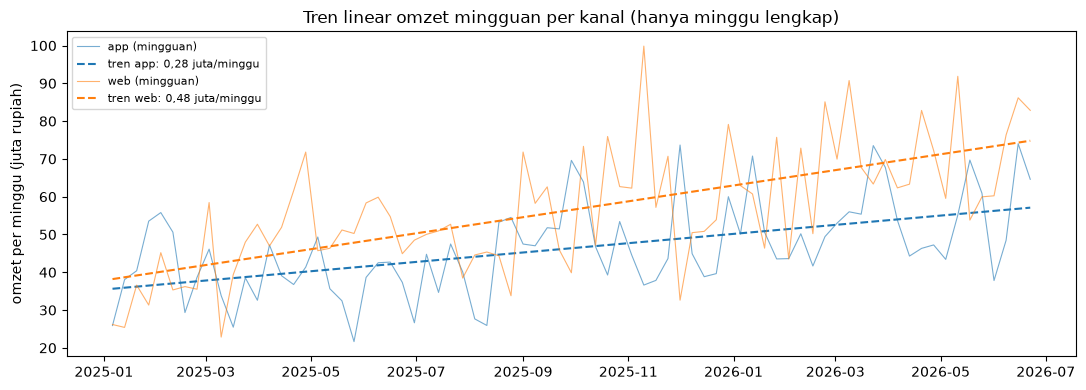

In [78]:
# TODO 1: lima tabel dasbor dan rekonsiliasi_m06.csv (setiap ukuran dicocokkan dengan pesanan_m06)
def ringkas(df, kunci):
    r = (df.groupby(kunci)
           .agg(pesanan=("id_pesanan", "nunique"), omzet=("total_bayar", "sum"),
                ongkir=("ongkir", "sum"), pelanggan=("id_entitas", "nunique"))
           .reset_index())
    r["aov"] = r.omzet / r.pesanan
    r["pangsa_omzet"] = r.omzet / r.omzet.sum()
    r["porsi_ongkir"] = r.ongkir / r.omzet
    return r
 
 
d_bulan = ringkas(selesai, "bulan")
d_bulan["hari"] = d_bulan.bulan.map(per_bulan.hari).astype(int)
d_bulan["omzet_per_hari"] = d_bulan.omzet / d_bulan.hari
d_provinsi = ringkas(selesai, "provinsi_tujuan").rename(columns={"provinsi_tujuan": "provinsi"})
d_kategori = ringkas(bs, "kategori")                       # butir baris; pesanan = nunique id_pesanan
d_kategori["baris"] = d_kategori.kategori.map(bs.groupby("kategori").size())
d_kanal = ringkas(selesai, "kanal")
 
d_status = (pesanan.groupby("status")
                   .agg(pesanan=("id_pesanan", "size"), total_bayar=("total_bayar", "sum"),
                        ongkir=("ongkir", "sum"), pelanggan=("id_entitas", "nunique"))
                   .reset_index())
d_status["aov"] = d_status.total_bayar / d_status.pesanan
d_status["pangsa_total"] = d_status.total_bayar / d_status.total_bayar.sum()
d_status["porsi_ongkir"] = d_status.ongkir / d_status.total_bayar
 
for nama, d in [("dasbor_bulanan", d_bulan), ("dasbor_provinsi", d_provinsi), ("dasbor_kategori", d_kategori),
                ("dasbor_kanal", d_kanal), ("dasbor_status", d_status)]:
    d.to_csv(OUT / f"{nama}_m06.csv", index=False)
 
CATATAN = {"pelanggan": "entitas yang sama muncul di lebih dari satu kelompok; jangan dijumlahkan, hitung nunique dari tabel pesanan",
           "pesanan": "pesanan multi-kategori terhitung di setiap kategorinya (lihat K-06-007); hitung dari tabel pesanan",
           "rasio": "rasio; dihitung ulang dari jumlah pembilang / jumlah penyebut, tidak dijumlahkan"}
rekon = []
 
 
def cek(tabel, ukuran, jumlah, acuan, atol=0.5, aditif=None, catatan=None):
    selisih = float(jumlah) - float(acuan)
    if aditif is None:
        aditif = bool(np.isclose(jumlah, acuan, rtol=1e-9, atol=atol))
    if catatan is None:
        catatan = "" if aditif else CATATAN.get(ukuran, "jumlah tidak cocok dengan acuan; periksa")
    rekon.append({"tabel": tabel, "ukuran": ukuran, "jumlah_tabel": float(jumlah), "acuan": float(acuan),
                  "selisih": selisih, "aditif": aditif, "catatan": catatan})
 
 
ACUAN_S = {"pesanan": N_SELESAI, "omzet": OMZET, "ongkir": float(selesai.ongkir.sum()),
           "pelanggan": int(selesai.id_entitas.nunique())}
for nama, d in [("dasbor_bulanan", d_bulan), ("dasbor_provinsi", d_provinsi),
                ("dasbor_kategori", d_kategori), ("dasbor_kanal", d_kanal)]:
    for u in ["pesanan", "omzet", "ongkir", "pelanggan"]:
        cek(nama, u, d[u].sum(), ACUAN_S[u])
    cek(nama, "pangsa_omzet", d.pangsa_omzet.sum(), 1.0, atol=1e-9)
    cek(nama, "aov", d.omzet.sum() / d.pesanan.sum(), AOV, atol=1e-6, aditif=False, catatan=CATATAN["rasio"])
 
ACUAN_A = {"pesanan": len(pesanan), "total_bayar": float(pesanan.total_bayar.sum()),
           "ongkir": float(pesanan.ongkir.sum()), "pelanggan": int(pesanan.id_entitas.nunique())}
for u in ["pesanan", "total_bayar", "ongkir", "pelanggan"]:
    cek("dasbor_status", u, d_status[u].sum(), ACUAN_A[u])
cek("dasbor_status", "pangsa_total", d_status.pangsa_total.sum(), 1.0, atol=1e-9)
 
rekonsiliasi = pd.DataFrame(rekon)
rekonsiliasi.to_csv(OUT / "rekonsiliasi_m06.csv", index=False)
assert rekonsiliasi[rekonsiliasi.ukuran.isin(["omzet", "total_bayar", "ongkir"])].aditif.all(), "rupiah tidak cocok"
print(rekonsiliasi[~rekonsiliasi.aditif][["tabel", "ukuran", "jumlah_tabel", "acuan", "aditif"]].to_string(index=False))
d_kategori.round(3)

# TODO 2: tren per kanal pada minggu lengkap -> tren_kanal_m06.csv, 06_tren_kanal.png
kanal_t = selesai.set_index("waktu_wib").sort_index()
baris_tren, kurva = [], {}
mingguan_kanal = {}
for kanal, d in kanal_t.groupby("kanal"):
    w = (d.total_bayar.resample("W-MON", label="left", closed="left").sum()
          .reindex(mingguan.index, fill_value=0))
    mingguan_kanal[kanal] = w
assert np.isclose(sum(w.sum() for w in mingguan_kanal.values()), OMZET)
mingguan_kanal["semua"] = mingguan.omzet.copy()
 
for kanal, w in mingguan_kanal.items():
    y = w[mingguan.lengkap] / 1e6
    t = tren(y)
    garis = t["intersep"] + t["kemiringan"] * np.arange(len(y))
    kurva[kanal] = (y, garis)
    baris_tren.append({"kanal": kanal, "n_minggu": t["n"], "kemiringan_juta_per_minggu": t["kemiringan"],
                       "intersep_juta": t["intersep"], "r2": t["r2"], "rata_minggu_juta": float(y.mean()),
                       "kemiringan_persen_dari_rata": 100 * t["kemiringan"] / float(y.mean()),
                       "tumbuh_tahunan_persen": 100 * 52 * t["kemiringan"] / float(garis[-1])})
tren_kanal = pd.DataFrame(baris_tren)
tren_kanal.to_csv(OUT / "tren_kanal_m06.csv", index=False)
 
fig, ax = plt.subplots(figsize=(11, 4))
for i, (kanal, (y, garis)) in enumerate([(k, v) for k, v in kurva.items() if k != "semua"]):
    ax.plot(y.index, y, lw=.8, color=f"C{i}", alpha=.6, label=f"{kanal} (mingguan)")
    ax.plot(y.index, garis, "--", color=f"C{i}",
            label=f"tren {kanal}: {angka(tren_kanal.set_index('kanal').kemiringan_juta_per_minggu[kanal], 2)} juta/minggu")
ax.set_ylabel("omzet per minggu (juta rupiah)"); ax.legend(fontsize=8)
ax.set_title("Tren linear omzet mingguan per kanal (hanya minggu lengkap)")
fig.tight_layout(); fig.savefig(OUT / "06_tren_kanal.png", dpi=110); plt.show()
B["tren_kanal"] = tren_kanal.set_index("kanal").to_dict("index")
tren_kanal.round(3)

# TODO 3: simulasi penarikan data 21 Juni 2026 -> periode_tidak_lengkap_m06.csv
cut = pd.Timestamp("2026-06-21 00:00")
tz = selesai.waktu_wib.dt.tz
if tz is not None:
    cut = cut.tz_localize(tz)
 
 
def skenario(nama, df, hari_juni):
    bln = df.set_index("waktu_wib").total_bayar.resample("MS").sum()
    mei, juni = float(bln.loc[pd.Timestamp("2026-05-01")]), float(bln.loc[pd.Timestamp("2026-06-01")])
    mei_hari, juni_hari = mei / 31, juni / hari_juni
    y_semua = bln / 1e6
    y_lengkap = y_semua if hari_juni == 30 else y_semua.iloc[:-1]       # buang Juni yang terpotong
    return {"skenario": nama, "hari_juni": hari_juni, "omzet_mei": mei, "omzet_juni": juni,
            "perubahan_bulanan_persen": 100 * (juni / mei - 1),
            "perubahan_per_hari_persen": 100 * (juni_hari / mei_hari - 1),
            "tren_bulanan_juta": tren(y_semua)["kemiringan"],
            "tren_bulan_lengkap_juta": tren(y_lengkap)["kemiringan"]}
 
 
potong = selesai[selesai.waktu_wib < cut]
hari_juni_potong = int((cut - pd.Timestamp("2026-06-01", tz=tz)).days)    # 20 hari teramati penuh
sim = pd.DataFrame([skenario("data_lengkap", selesai, 30),
                    skenario("terpotong_21_juni", potong, hari_juni_potong)])
sim.to_csv(OUT / "periode_tidak_lengkap_m06.csv", index=False)
B["sim"] = sim.set_index("skenario").to_dict("index")
print(f"pesanan selesai terpotong: {len(potong)} dari {len(selesai)}; hari Juni teramati: {hari_juni_potong}")
sim.round(2).T

# TODO 4: catat_keputusan([...]) untuk keputusan Latihan dan Tugas (K-06-009 dan seterusnya)
sm, sl = B["sim"]["terpotong_21_juni"], B["sim"]["data_lengkap"]
t_kn = B["tren_kanal"]
log = catat_keputusan([
    {"id": "K-06-009", "modul": 6, "sumber_kolom": "pesanan_m06.id_entitas;pesanan_m06.bulan",
     "temuan": "kohort pelanggan hanya dapat dibentuk dari pembeli terdaftar; sel kohort di luar rentang data belum teramati",
     "bukti": (f"{B['selesai_tamu']} pesanan selesai pembeli tamu ({juta(B['selesai_tamu_rp'])}) dikeluarkan; ukuran kohort total {B['ukuran_total_entitas']}; "
               f"retensi bulan ke-1 sederhana {angka(100*B['ret1_sederhana'], 2)}% vs tertimbang {angka(100*B['ret1_tertimbang'], 2)}%; "
               f"bulan ke-6 NaN dibiarkan {angka(100*B['ret6_dibiarkan'], 2)}% vs diisi 0 {angka(100*B['ret6_isi0'], 2)}%"),
     "tindakan": "kohort = transform('min') bulan pesanan selesai per id_entitas; sel belum teramati dibiarkan NaN dan tidak ditulis ke kohort_m06.csv; retensi dilaporkan tertimbang",
     "alasan": "mengisi 0 memperlakukan 'belum teramati' sebagai 'tidak kembali'; rata-rata sederhana memberi bobot sama pada kohort kecil dan besar",
     "baris_terdampak": B["selesai_tamu"], "id_anomali": "-"},
    {"id": "K-06-010", "modul": 6, "sumber_kolom": "dasbor_*_m06.csv;rekonsiliasi_m06.csv",
     "temuan": "ukuran pesanan, pelanggan, dan rasio tidak aditif lintas kelompok pada tabel dasbor",
     "bukti": (f"pesanan dijumlah lintas kategori {B['pesanan_dijumlah_kategori']} vs {B['n_selesai']} pesanan; "
               f"ukuran tidak aditif tercatat pada {int((~rekonsiliasi.aditif).sum())} baris rekonsiliasi_m06.csv"),
     "tindakan": "setiap ukuran dicocokkan dengan pesanan_m06; yang tidak cocok diberi aditif=False dan dijelaskan; rasio dihitung ulang dari jumlah pembilang/penyebut",
     "alasan": "pesanan multi-kategori dan pelanggan lintas kelompok terhitung berkali-kali; menjumlahkannya menggelembungkan total",
     "baris_terdampak": int((~rekonsiliasi.aditif).sum()), "id_anomali": "-"},
    {"id": "K-06-011", "modul": 6, "sumber_kolom": "pesanan_m06.id_pelanggan;pesanan_m06.id_entitas",
     "temuan": "kunci id_pelanggan memecah satu orang pengguna web dan aplikasi menjadi dua pelanggan pada analisis kohort",
     "bukti": (f"ukuran kohort total {B['ukuran_total_id']} (id_pelanggan) vs {B['ukuran_total_entitas']} (id_entitas); "
               f"retensi bulan ke-1 {angka(100*B['ret1_tertimbang_id'], 2)}% vs {angka(100*B['ret1_tertimbang'], 2)}%"),
     "tindakan": "analisis kohort dan hitung pelanggan memakai id_entitas",
     "alasan": "id_entitas menyatukan identitas lintas kanal sehingga pelanggan dan retensi tidak terbelah",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-06-012", "modul": 6, "sumber_kolom": "pesanan_m06.waktu_wib;pesanan_m06.kanal",
     "temuan": "tren omzet per kanal berbeda; minggu tidak lengkap dikeluarkan dari regresi",
     "bukti": "; ".join(f"{k}: {angka(v['kemiringan_juta_per_minggu'], 3)} juta/minggu, R2 {angka(v['r2'], 2)}, {angka(v['tumbuh_tahunan_persen'])}% setahun"
                         for k, v in t_kn.items()),
     "tindakan": "omzet mingguan per kanal (Senin-Minggu, WIB) di-reindex ke seluruh minggu agar minggu tanpa pesanan bernilai 0; regresi hanya pada minggu lengkap; jumlah kanal direkonsiliasi dengan omzet mingguan total",
     "alasan": "minggu terpotong bukan penurunan penjualan; tren linear hanya gambaran kemiringan, bukan ramalan",
     "baris_terdampak": len(B["minggu_tak_lengkap"]), "id_anomali": "-"},
    {"id": "K-06-013", "modul": 6, "sumber_kolom": "pesanan_m06.waktu_wib",
     "temuan": "bulan berjalan yang terpotong tampak sebagai penurunan bila dibandingkan dengan omzet bulanan",
     "bukti": (f"data ditarik 21 Juni 2026: Juni vs Mei omzet bulanan {angka(sm['perubahan_bulanan_persen'])}% (data lengkap {angka(sl['perubahan_bulanan_persen'])}%); "
               f"per hari {angka(sm['perubahan_per_hari_persen'])}% (data lengkap {angka(sl['perubahan_per_hari_persen'])}%); "
               f"tren bulanan {angka(sm['tren_bulanan_juta'], 2)} juta (dengan Juni) vs {angka(sm['tren_bulan_lengkap_juta'], 2)} juta (tanpa Juni terpotong)"),
     "tindakan": "perbandingan antarbulan memakai omzet per hari; bulan tidak lengkap ditandai dan dikeluarkan dari regresi tren, tetapi tidak dari tabel",
     "alasan": "bulan yang baru berjalan sebagian membandingkan 20 hari dengan 31 hari",
     "baris_terdampak": len(selesai) - len(potong), "id_anomali": "-"},
])
print("baris K-06:", int(log.id.str.startswith("K-06").sum()), "(minimal 10)")
log[log.id.str.startswith("K-06")][["id", "sumber_kolom", "baris_terdampak"]]

# TODO 5: laporan.md (ditulis di luar notebook, pada folder modul)